# Хроматичность и Twiss-функции magnetic_2_md: OptiM, BELL, COSY, MAD-X
Решётка `C:\GIT_REPOS\SCT_2\lattice\magnetic_2_md.opt`, дейтрон m = 1875.612945 МэВ, W = 270 МэВ,
γ0 = 1.143952941, β0 = 0.485634729, Bρ = 3.47568504 Т·м.

**Общее определение:** ξ = dQ/dδ, δ = dp/p, натуральная (секступоли = 0), первый порядок; eta = ΔT/T/δ = alpha_c − 1/γ².
Пересчёты: COSY δ_K = ΔK/K = (1+1/γ)δ ⇒ ξ = (1+1/γ)·dQ/dδ_K = 1.874162·raw; MAD-X TWISS: PT = β0·δ ⇒ ξ = β0·DQ = 0.485635·DQ.

Структура: (1) каждый запуск отдельно — команда, сырой вывод, что берём, пересчёт; (2) сводная таблица;
(3) Twiss-функции всех программ; (4) почему ξy различается.

In [1]:
import re, json, pathlib, subprocess, sys
import numpy as np, pandas as pd, matplotlib.pyplot as plt
R = pathlib.Path(r"C:\GIT_REPOS\SCT_2\chromaticity")
G0 = 1 + 270/1875.612945; B0 = np.sqrt(1 - 1/G0**2); F = 1 + 1/G0
pd.set_option("display.precision", 6); pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 70)
def show(path, pat=None, first=None):
    """print raw lines of an output file (optionally only lines matching regex pat)"""
    p = R/path; print(f"----- {p} -----")
    lines = p.read_text(encoding="utf-8", errors="replace").splitlines()
    if pat: lines = [l for l in lines if re.search(pat, l)]
    for l in lines[:first]: print(l)
def kv(path):
    d = {}
    for l in (R/path).read_text(encoding="utf-8-sig").splitlines():
        m = re.match(r"\s*(\w+)\s*=\s*([-+0-9.Ee]+)\s*$", l)
        if m: d[m[1]] = float(m[2])
    return d
def tfs(path):
    lines = (R/path).read_text().splitlines()
    hdr = next(l for l in lines if l.startswith("*")).split()[1:]
    rows = [l.split() for l in lines if not l.startswith(("@", "*", "$"))]
    return pd.DataFrame(rows, columns=hdr)
ROWS = []   # (program, method, Qx, Qy, alpha_c, eta, xi_x, xi_y)
def add(*r):
    ROWS.append(r); print("-> row:", r)
print(f"gamma0={G0:.9f} beta0={B0:.9f} 1+1/gamma0={F:.9f}")
from IPython.display import Code, display
def src(path, lang, a=None, b=None):
    """show source file (lines a..b, 1-based) with syntax highlighting"""
    p = pathlib.Path(path); p = p if p.is_absolute() else R/p
    L = p.read_text(encoding="utf-8", errors="replace").splitlines()
    print(f"{p}  (lines {a or 1}-{b or len(L)})")
    display(Code("\n".join(L[(a or 1)-1:b]), language=lang))

gamma0=1.143952941 beta0=0.485634729 1+1/gamma0=1.874161833


## 1. OptiM (эталон, GUI)
**Запуск:** `OptiM\run_optim.bat` открывает `magnetic_2_md.opt` в OptiMX (только GUI, без пакетного режима), Twiss — вручную.
**Вывод:** окно OptiM, переписано пользователем в `OptiM/output/optim_reference.txt`.
**Берём:** Tunes, Momentum compaction, Phase Slip Factor, Chromaticities. OptiM уже даёт ξ = dQ/d(dp/p) — пересчёт не нужен.

In [2]:
show("OptiM/output/optim_reference.txt")
t = (R/"OptiM/output/optim_reference.txt").read_text(encoding="utf-8-sig")
g = lambda p: float(re.search(p, t)[1])
add("OptiM", "GUI Twiss (linear formulas, hard-edge bends)", g(r"Qx =\s*([-\d.]+)"), g(r"Qy =\s*([-\d.]+)"),
    g(r"compaction :\s*([-\d.]+)"), g(r"Slip Factor :\s*([-\d.]+)"), g(r"Chromaticities :\s*([-\d.]+)"), g(r"\(hor\)\s*([-\d.]+)"))

----- C:\GIT_REPOS\SCT_2\chromaticity\OptiM\output\optim_reference.txt -----
﻿# OptiM reference output (GUI, entered by user Bell from OptiM window)
# file: magnetic_2_md.opt ; OptiM: C:\Program Files\OptiMX-x86-64\optimx64.exe
# chromaticity = dQ/d(dp/p), natural (sextupoles = 0), linear (1st order)
Total Length : 	    11738.8 cm
Tunes : 	Qx =    2.46172,  Qy =    2.46134
Momentum compaction : 	   0.23047
Phase Slip Factor : 	 -0.533689
Chromaticities : 	  -1.46153 (hor) 	  -1.81705 (ver)
Initial Energy : 	       270 MeV
Final Energy : 	       270 MeV
-> row: ('OptiM', 'GUI Twiss (linear formulas, hard-edge bends)', 2.46172, 2.46134, 0.23047, -0.533689, -1.46153, -1.81705)


## 2. BELL (Julia)
**Запуск:** `BELL\run_bell.bat` = `julia --project=C:\GIT_REPOS\BELL\Julia chrom_bell.jl` (BELL v0.10.0 как есть).
Читает .opt через `convert_optim` → `magnetic_2_md.bell`. Вывод: `BELL/output/bell_results.txt`, `bell_twiss.csv`.
δ в BELL = dp/p (канонический), поэтому ξ берётся без пересчёта. Модель диполя: только тело, без краевого члена.

In [3]:
show("BELL/output/bell_results.txt")
bell = kv("BELL/output/bell_results.txt")

----- C:\GIT_REPOS\SCT_2\chromaticity\BELL\output\bell_results.txt -----
# BELL (Julia) results for C:\GIT_REPOS\SCT_2\lattice\magnetic_2_md.opt
# reference: mass=1875.61294257 MeV Ekin=270.0000 MeV gamma=1.143952941 beta=0.485634729 p=1041.984160 MeV/c Brho=3.47568503 T*m
# delta = dp/p (canonical momentum deviation); xi = dQ/ddelta (central difference of Jacobian tunes on off-momentum closed orbit)
C_m = 117.3882960
linear_Qx = 2.46172014
linear_Qy = 2.46133732
linear_alpha_c = 0.23047028
linear_eta = -0.53368863
taylor_alpha0 = 0.23047028
taylor_alpha1 = 0.33900771
taylor_eta0 = -0.53368863
taylor_eta1 = 1.01716074
taylor_Qx_frac = 0.46172014
taylor_xi_x = -1.461538
taylor_xi2_x = 8.5547
taylor_Qy_frac = 0.46133732
taylor_xi_y = -2.225488
taylor_xi2_y = 8.1041
lie_Qx = 0.46172014
lie_Qy = 0.46133732
lie_alpha0 = 0.23047028
lie_eta0 = -0.53368863
lie_xi_x = -1.461538
lie_xi_y = -2.225488
lie_xi2_x = 8.5547
lie_xi2_y = 8.1041
# taylor map built in 1.5 s


**Код BELL.** Скрипт запуска `chrom_bell.jl` и функции ядра BELL, которые реально считают хроматичность
(`C:\GIT_REPOS\BELL\Julia\src\higher_order.jl`: `closed_orbit`, `_frac_tune`, `tunes_at_delta`, `path_expansion`, `chromaticity_orders`; только чтение).

In [4]:
src("BELL/chrom_bell.jl", "julia")
src(r"C:\GIT_REPOS\BELL\Julia\src\higher_order.jl", "julia", 34, 106)

C:\GIT_REPOS\SCT_2\chromaticity\BELL\chrom_bell.jl  (lines 1-52)


# chrom_bell.jl -- tunes, alpha_c, eta, chromaticity of magnetic_2_md via BELL (as-is)
#   julia --project=C:\GIT_REPOS\BELL\Julia chrom_bell.jl
using Bell, Printf, LinearAlgebra, TaylorSeries

const OPT  = raw"C:\GIT_REPOS\SCT_2\lattice\magnetic_2_md.opt"
const STR  = joinpath(@__DIR__, "magnetic_2_md.bell")
const OUT  = joinpath(@__DIR__, "output", "bell_results.txt")
mkpath(dirname(OUT))

of  = convert_optim(OPT, STR)          # BELL OptiM reader -> .bell structure
lat = load_structure(STR)
ref = lat.ref
C   = circumference(lat)
foreach(w -> println("WARNING: ", w), of.warnings)

# (A) linear optics: one-turn matrix
R  = ring_matrix(lat)
po = periodic_optics(R, ref, C)
opt = optics_along(lat, po)

# (B) one-turn Taylor map (RK4 in truncated polynomials), chromaticity_orders
t0 = time(); M = ring_taylor_map(lat); tM = time() - t0
pe = path_expansion(M, ref, C)
ch = chromaticity_orders(M)

# (C) one-turn Lie factor (Lie map) -> polynomial -> same readers
obs = observables(lat)

io = open(OUT, "w")
for s in (stdout, io)
  @printf(s, "# BELL (Julia) results for %s\n", OPT)
  @printf(s, "# reference: mass=%.8f MeV Ekin=%.4f MeV gamma=%.9f beta=%.9f p=%.6f MeV/c Brho=%.8f T*m\n",
          ref.mass_MeV, ref.Ekin_MeV, ref.gamma, ref.beta, ref.p0_MeV, ref.brho_Tm)
  @printf(s, "# delta = dp/p (canonical momentum deviation); xi = dQ/ddelta (central difference of Jacobian tunes on off-momentum closed orbit)\n")
  @printf(s, "C_m = %.7f\n", C)
  @printf(s, "linear_Qx = %.8f\nlinear_Qy = %.8f\n", opt.Qx, opt.Qy)
  @printf(s, "linear_alpha_c = %.8f\nlinear_eta = %.8f\n", po.alpha_c, po.eta_slip)
  @printf(s, "taylor_alpha0 = %.8f\ntaylor_alpha1 = %.8f\ntaylor_eta0 = %.8f\ntaylor_eta1 = %.8f\n", pe.alpha0, pe.alpha1, pe.eta0, pe.eta1)
  @printf(s, "taylor_Qx_frac = %.8f\ntaylor_xi_x = %.6f\ntaylor_xi2_x = %.4f\n", ch.x...)
  @printf(s, "taylor_Qy_frac = %.8f\ntaylor_xi_y = %.6f\ntaylor_xi2_y = %.4f\n", ch.y...)
  @printf(s, "lie_Qx = %.8f\nlie_Qy = %.8f\nlie_alpha0 = %.8f\nlie_eta0 = %.8f\n", obs.po.x.mu/2pi, obs.po.y.mu/2pi, obs.pe.alpha0, obs.pe.eta0)
  @printf(s, "lie_xi_x = %.6f\nlie_xi_y = %.6f\nlie_xi2_x = %.4f\nlie_xi2_y = %.4f\n", obs.xi.x[2], obs.xi.y[2], obs.xi.x[3], obs.xi.y[3])
  @printf(s, "# taylor map built in %.1f s\n", tM)
end
close(io)
open(joinpath(@__DIR__, "output", "bell_twiss.csv"), "w") do f
  println(f, "s_m,betx_m,bety_m,Dx_m")           # D per dp/p, at element boundaries (optics_along)
  for k in eachindex(opt.data.s)
    @printf(f, "%.9f,%.9f,%.9f,%.9e\n", opt.data.s[k], opt.data.betx[k], opt.data.bety[k], opt.data.D[k])
  end
end
println("written ", OUT)

C:\GIT_REPOS\BELL\Julia\src\higher_order.jl  (lines 34-106)


"4D closed orbit (x,px,y,py) at fixed delta; l is irrelevant (no RF)."
function closed_orbit(M, d::Real; iters = 30)
    u = zeros(4)
    for _ in 1:iters
        z = [u; 0.0; d]
        F = _evalpt(M, z)[1:4] .- u
        J = _jac(M, z)[1:4, 1:4] - I
        du = -J \ F
        u .+= du
        maximum(abs, du) < 1e-16 && break
    end
    return u
end

function _frac_tune(m)
    c = (m[1, 1] + m[2, 2]) / 2
    s = sign(m[1, 2]) * sqrt(max(0.0, 1 - c^2))
    return mod(atan(s, c), 2pi) / 2pi
end

"Fractional tunes of the Jacobian on the closed orbit at momentum deviation delta."
function tunes_at_delta(M, d::Real)
    u = closed_orbit(M, d)
    J = _jac(M, [u; 0.0; d])
    return (_frac_tune(J[1:2, 1:2]), _frac_tune(J[3:4, 3:4]), u)
end

"delta^k coefficient helper: quadratic part of M_i evaluated at vector w."
_q(M, i, w) = evaluate(TaylorN(M[i][2], JET_ORDER), w)

function dispersion_orders(M)
    R = map_linear_part(M)
    A = I - R[1:4, 1:4]
    D1 = A \ R[1:4, 6]
    w = [D1; 0.0; 1.0]
    D2 = A \ [_q(M, i, w) for i in 1:4]
    return (D1 = D1, D2 = D2, w = w, R = R)
end

"v/v0 - 1 = c1 d + c2 d^2 + c3 d^3 (exact Taylor of velocity_ratio)."
function velocity_expansion(ref::RefParticle)
    g2 = ref.gamma^2; b2 = ref.beta^2
    c1 = 1 / g2
    c2 = -1.5 * b2 / g2
    c3 = 0.5 * b2 * (5b2 - 1) / g2
    return c1, c2, c3
end

"""
path_expansion to order 2 (alpha0, alpha1) from the truncated map.
alpha_i defined by C(delta)/C0 = 1 + alpha0 d + alpha1 d^2 + alpha2 d^3
with Delta l = -C(d) + C0 (v/v0) on the closed orbit.
"""
function path_expansion(M, ref::RefParticle, C::Real)
    d = dispersion_orders(M)
    R = d.R
    l1 = dot(R[5, 1:4], d.D1) + R[5, 6]
    l2 = dot(R[5, 1:4], d.D2) + _q(M, 5, d.w)
    c1, c2, c3 = velocity_expansion(ref)
    alpha0 = -l1 / C + c1
    alpha1 = -l2 / C + c2
    eta0 = -l1 / C
    eta1 = -l2 / C + (l1 / C) * c1
    eta1_formula = alpha1 - alpha0 * c1 - c2 + c1^2
    return (l1 = l1, l2 = l2, alpha0 = alpha0, alpha1 = alpha1, eta0 = eta0, eta1 = eta1,
            eta1_formula = eta1_formula, gamma_t = 1 / sqrt(abs(alpha0)), c1 = c1, c2 = c2, c3 = c3)
end

function chromaticity_orders(M; dd = 1e-4)
    q0 = tunes_at_delta(M, 0.0); qp = tunes_at_delta(M, dd); qm = tunes_at_delta(M, -dd)
    f(k) = (q0[k], (qp[k] - qm[k]) / (2dd), (qp[k] - 2 * q0[k] + qm[k]) / dd^2)
    return (x = f(1), y = f(2))     # (Q0_frac, xi1, xi2 = d2Q/ddelta2)
end

### 2a. BELL, одно-оборотная матрица (линейно)
Строки `linear_Qx/Qy` (целая часть из набега фазы), `linear_alpha_c`, `linear_eta`. Хроматичность этим методом не считается.

In [5]:
add("BELL", "one-turn matrix (linear)", bell["linear_Qx"], bell["linear_Qy"], bell["linear_alpha_c"], bell["linear_eta"], np.nan, np.nan)

-> row: ('BELL', 'one-turn matrix (linear)', 2.46172014, 2.46133732, 0.23047028, -0.53368863, nan, nan)


### 2b. BELL, отображение Тейлора 3-го порядка (`ring_taylor_map`)
`taylor_Qx_frac` — дробный тюн (+2 целая часть), `taylor_alpha0`, `taylor_eta0` — из `path_expansion`,
`taylor_xi_x/y` — `chromaticity_orders`: центральная разность ±1e-4 тюнов якобиана на замкнутой орбите при δ.

In [6]:
add("BELL", "Taylor map o3, Q(δ) central diff", 2+bell["taylor_Qx_frac"], 2+bell["taylor_Qy_frac"], bell["taylor_alpha0"], bell["taylor_eta0"], bell["taylor_xi_x"], bell["taylor_xi_y"])

-> row: ('BELL', 'Taylor map o3, Q(δ) central diff', 2.46172014, 2.46133732, 0.23047028, -0.53368863, -1.461538, -2.225488)


### 2c. BELL, Ли-фактор (`observables`: `ring_lie_factor` → `factor_to_map`)
Те же читалки, другое построение одно-оборотного отображения. Строки `lie_*`.

In [7]:
add("BELL", "Lie factor map, Q(δ) central diff", 2+bell["lie_Qx"], 2+bell["lie_Qy"], bell["lie_alpha0"], bell["lie_eta0"], bell["lie_xi_x"], bell["lie_xi_y"])

-> row: ('BELL', 'Lie factor map, Q(δ) central diff', 2.46172014, 2.46133732, 0.23047028, -0.53368863, -1.461538, -2.225488)


## 3. COSY INFINITY 10.2
**Запуск:** `COSY\run_cosy.bat`: `lattice_md.fox` (решётка, один раз → `lattice_md.bin`), `ov321.fox`, `ov330.fox`, `twiss.fox`,
(`rf_test.fox` по аргументу), затем `python ov330_map_analysis.py`. Элементы: `DL`, `MS` (секторный, 22.5°, без краевых углов),
`MQ`, `MH` (0), `FR 0` (жёсткий край без fringe). Переменная энергии COSY: δ_K = ΔK/K.

In [8]:
src("COSY/lattice_md.fox", "pascal")

C:\GIT_REPOS\SCT_2\chromaticity\COSY\lattice_md.fox  (lines 1-38)


{ lattice_md.fox - magnetic_2_md ring (lattice/magnetic_2_md.opt), compiled once -> lattice_md.bin }
INCLUDE 'C:/GIT_REPOS/SCT_2/COSY/src/COSY';            { COSY 10.2 system (compiled cosy.bin) }

PROCEDURE PART EK;                                     { reference deuteron, EK = kinetic energy [MeV] (may be DA) }
  RP EK 1875.612945/AMUMEV 1;                          { mass CODATA 2022 in amu, charge 1 }
ENDPROCEDURE;

PROCEDURE RING TW U B0X A0X B0Y A0Y D0 DP0;            { one turn; TW=1: write Twiss after each element to unit U }
  VARIABLE AP 1; VARIABLE LB 1; VARIABLE RB 1; VARIABLE S 1;
  PROCEDURE WR NAME;                                   { Twiss at element exit from the accumulated map }
    VARIABLE BX 1; VARIABLE BY 1; VARIABLE DX 1;
    IF TW=1;
      BX := (ME(1,1)*ME(1,1)*B0X - 2*ME(1,1)*ME(1,2)*A0X + ME(1,2)*ME(1,2)*(1+A0X*A0X)/B0X);
      BY := (ME(3,3)*ME(3,3)*B0Y - 2*ME(3,3)*ME(3,4)*A0Y + ME(3,4)*ME(3,4)*(1+A0Y*A0Y)/B0Y);
      DX := ME(1,1)*D0 + ME(1,2)*DP0 + ME(1,6);        { per delta_K }
      WRITE U NAME&' '&ST(SPOS)&' '&ST(BX)&' '&ST(BY)&' '&ST(DX);
    ENDIF;
  ENDPROCEDURE;
  PROCEDURE BM;  MS RB 22.5 AP 0 0 0 0 0; WR 'BM';  ENDPROCEDURE;  { sector bend 22.5 deg, no edge angles }
  PROCEDURE OBM; DL LB;   WR 'OBM'; ENDPROCEDURE;      { drift of dipole length }
  PROCEDURE OS1; DL 0.12; WR 'OS1'; ENDPROCEDURE;
  PROCEDURE OS2; DL 0.06; WR 'OS2'; ENDPROCEDURE;
  PROCEDURE SX N; MH 0.12 0 AP; WR N; ENDPROCEDURE;    { SF1/SF2/SD, strength 0 }
  PROCEDURE QF;  MQ 0.21  1.81168058*AP AP; WR 'QF';  ENDPROCEDURE;  { pole field = G[T/m]*aperture }
  PROCEDURE QD;  MQ 0.21 -2.01793283*AP AP; WR 'QD';  ENDPROCEDURE;
  PROCEDURE QF1; MQ 0.21  1.93455213*AP AP; WR 'QF1'; ENDPROCEDURE;
  PROCEDURE QD1; MQ 0.21 -1.93455213*AP AP; WR 'QD1'; ENDPROCEDURE;
  PROCEDURE ARC;
    OS2; QF; BM; QD; OS1; QD; BM; QF; SX 'SF2';
    QF; BM; QD; SX 'SD'; QD; BM; QF; SX 'SF1';
    QF; BM; QD; SX 'SD'; QD; BM; QF; SX 'SF2';
    QF; BM; QD; OS1; QD; BM; QF; OS2;
  ENDPROCEDURE;
  PROCEDURE STR; OS2; QF1; OBM; QD1; OS1; QD1; OBM; QF1; OS2; ENDPROCEDURE;
  AP := 0.05; LB := 5.3294148; RB := LB/(22.5*PI/180);
  UM; ARC; STR; ARC; STR;                              { full ring, 1 period }
ENDPROCEDURE;
SAVE 'lattice_md';

In [9]:
src("COSY/run_cosy.bat", "bat")

C:\GIT_REPOS\SCT_2\chromaticity\COSY\run_cosy.bat  (lines 1-12)


@echo off
rem COSY 10.2: cosy.exe from C:\GIT_REPOS\SCT_2\COSY\src (its cosy.bin is INCLUDEd by absolute path)
cd /d %~dp0
set COSY=C:\GIT_REPOS\SCT_2\COSY\src\cosy.exe
%COSY% lattice_md.fox > output\lattice_md.log 2>&1
%COSY% ov321.fox > output\ov321.log 2>&1
%COSY% ov330.fox > output\ov330.log 2>&1
%COSY% ov321_user_method.fox > output\ov321_user_method.log 2>&1
%COSY% twiss.fox > output\twiss.log 2>&1
if not "%1"=="" %COSY% rf_test.fox > output\rf_test.log 2>&1
python ov330_map_analysis.py

### 3a. COSY OV 3 2 1, TP
`ov321.fox`: `OV 3 2 1`, `PART 270*PARA(1)` (энергия — DA-параметр), `TP MU`. Берём `CONS(MU)` = дробный тюн и
`MU|(0,0,0,0,1)` = dQ/dδ_K (сырое), ξ = (1+1/γ)·raw.

In [10]:
src("COSY/ov321.fox", "pascal"); show("COSY/output/cosy_ov321.txt")
c1 = kv("COSY/output/cosy_ov321.txt")
print(f"xi_x = {c1['factor_1p1g']:.9f} * {c1['dQx_ddK_raw']:.9f} = {c1['xi_x_p']:.9f};  xi_y = {c1['factor_1p1g']:.9f} * {c1['dQy_ddK_raw']:.9f} = {c1['xi_y_p']:.9f}")
add("COSY", "OV 3 2 1, TP, ×(1+1/γ)", 2+c1["Qx_frac"], 2+c1["Qy_frac"], np.nan, np.nan, c1["xi_x_p"], c1["xi_y_p"])

C:\GIT_REPOS\SCT_2\chromaticity\COSY\ov321.fox  (lines 1-23)


{ ov321.fox - chromaticity by TP, energy as DA parameter }
INCLUDE 'lattice_md';
PROCEDURE RUN;
  VARIABLE MU 1000 2; VARIABLE G 1; VARIABLE F 1;
  OV 3 2 1;                                  { order 3, 2 phase-space planes, 1 parameter }
  FR 0;                                      { hard edge, no fringe }
  PART 270*PARA(1);                          { EK = 270 MeV * (1 + delta_K) }
  RING 0 0 0 0 0 0 0 0;
  TP MU;                                     { tunes as functions of delta_K }
  G := 1+270/1875.612945; F := 1+1/G;        { delta_K = (1+1/gamma) delta_p }
  OPENF 20 'output/cosy_ov321.txt' 'UNKNOWN';
  WRITE 20 'length = '&ST(SPOS);
  WRITE 20 'gamma0 = '&ST(G);
  WRITE 20 'factor_1p1g = '&ST(F);
  WRITE 20 'Qx_frac = '&ST(CONS(MU(1)));
  WRITE 20 'Qy_frac = '&ST(CONS(MU(2)));
  WRITE 20 'dQx_ddK_raw = '&ST(MU(1)|(0&0&0&0&1));
  WRITE 20 'dQy_ddK_raw = '&ST(MU(2)|(0&0&0&0&1));
  WRITE 20 'xi_x_p = '&ST(F*(MU(1)|(0&0&0&0&1)));
  WRITE 20 'xi_y_p = '&ST(F*(MU(2)|(0&0&0&0&1)));
  CLOSEF 20;
ENDPROCEDURE;
RUN; END;

----- C:\GIT_REPOS\SCT_2\chromaticity\COSY\output\cosy_ov321.txt -----
length =  117.3882959999999
gamma0 =  1.143952941207707
factor_1p1g =  1.874161833042073
Qx_frac = 0.4617201483757378
Qy_frac = 0.4613373212771295
dQx_ddK_raw = -.7798343176488987
dQy_ddK_raw = -1.187456115456067
xi_x_p = -1.461535714233974
xi_y_p = -2.225484930000162
xi_x = 1.874161833 * -0.779834318 = -1.461535714;  xi_y = 1.874161833 * -1.187456115 = -2.225484930
-> row: ('COSY', 'OV 3 2 1, TP, ×(1+1/γ)', 2.461720148375738, 2.4613373212771297, nan, nan, -1.461535714233974, -2.225484930000162)


### 3b. COSY OV 3 3 0: дамп 6D-отображения и коэффициенты
`ov330.fox`: `OV 3 3 0`, `PART 270`, `PM` → `map_ov330.txt`, коэффициенты MAP(1..6) полной точности → `map_ov330_full.txt`.
`ov330_map_analysis.py` строит из них: линейный блок, хроматические члены 2-го порядка, (i) замкнутую орбиту при δ_K и тюны якобиана,
(ii) 4D-отображение с δ_K как параметром, собственные числа 6×6, eta и alpha_c из (l|δ_K) на замкнутой орбите.
TP здесь не работает: продольный блок [[1, 17.836],[0,1]] — жорданова клетка (собственные числа 1,1), 6D нормальной формы нет.

In [11]:
src("COSY/ov330.fox", "pascal"); src("COSY/ov330_map_analysis.py", "python"); show("COSY/output/map_ov330.txt", first=24)

C:\GIT_REPOS\SCT_2\chromaticity\COSY\ov330.fox  (lines 1-14)


{ ov330.fox - full 6D one-turn map (x,a,y,b,l,delta_K), dumped for ov330_map_analysis.py }
INCLUDE 'lattice_md';
PROCEDURE RUN;
  OV 3 3 0;                                  { order 3, 3 phase-space planes, no parameters }
  FR 0;
  PART 270;
  RING 0 0 0 0 0 0 0 0;
  OPENF 30 'output/map_ov330.txt' 'UNKNOWN'; PM 30; CLOSEF 30;          { COSY map listing }
  OPENF 31 'output/map_ov330_full.txt' 'UNKNOWN';                       { full-precision coefficients }
  WRITE 31 'GAMMA0 '&ST(1+270/1875.612945); WRITE 31 'LENGTH '&ST(SPOS);
  WRITE 31 MAP(1) MAP(2) MAP(3) MAP(4) MAP(5) MAP(6);
  CLOSEF 31;
ENDPROCEDURE;
RUN; END;

C:\GIT_REPOS\SCT_2\chromaticity\COSY\ov330_map_analysis.py  (lines 1-108)


"""Analysis of the COSY OV 3 3 0 one-turn map (output/map_ov330_full.txt).
Coordinates (COSY): x, a, y, b, l, dK (dK = delta_K = dK/K)."""
import re, numpy as np, itertools, json, pathlib
P = pathlib.Path(__file__).parent/"output"
txt = (P/"map_ov330_full.txt").read_text().splitlines()
g = float(txt[0].split()[1]); C = float(txt[1].split()[1]); F = 1+1/g
maps, cur = [], None
for l in txt[2:]:
    if l.strip().startswith("I "): cur = {}; maps.append(cur); continue
    if l.strip().startswith("---") or not l.strip(): continue
    t = l.split()
    if len(t) >= 9: cur[tuple(map(int, t[3:9]))] = float(t[1])
# identity rows that COSY prints as empty
names = ["x","a","y","b","l","dK"]
def coef(i, e): return maps[i].get(tuple(e), 0.0)
def mon(e): return "".join(n*k if k<=1 else f"{n}^{k}" for n,k in zip(names,e)) if any(e) else "1"
out = []
def pr(*s):
    s = " ".join(str(v) for v in s); print(s); out.append(s)
pr(f"gamma0 = {g:.12f}, C = {C:.9f} m, 1+1/gamma0 = {F:.12f}")
# ---- 1. linear 6x6
M = np.zeros((6,6))
for i in range(6):
    for j in range(6):
        e=[0]*6; e[j]=1; M[i,j]=coef(i,e)
pr("\n## 1. Linear part R (rows: final x,a,y,b,l,dK; cols: initial)")
pr("        " + "".join(f"{n:>16s}" for n in names))
for i in range(6): pr(f"{names[i]:>6s}  " + "".join(f"{M[i,j]:16.9e}" for j in range(6)))
pr("\nkey linear terms:")
for (i,j) in [(0,5),(1,5),(4,0),(4,1),(4,5)]: pr(f"  ({names[i]}|{names[j]}) = {M[i,j]: .12e}")
pr("\n## 2. Second-order chromatic terms (i | j dK)")
for i in range(4):
    for j in range(4):
        e=[0]*6; e[j]+=1; e[5]+=1; v=coef(i,e)
        if v!=0: pr(f"  ({names[i]}|{names[j]} dK) = {v: .12e}")
for i in range(2):
    e=[0]*6; e[5]=2; pr(f"  ({names[i]}|dK dK) = {coef(i,e): .12e}")
pr("geometric 2nd-order terms used on the closed orbit:")
for i,(e) in itertools.product(range(4),[(2,0,0,0,0,0),(1,1,0,0,0,0),(0,2,0,0,0,0),(1,0,1,0,0,0),(1,0,0,1,0,0),(0,1,1,0,0,0),(0,1,0,1,0,0)]):
    v=coef(i,e)
    if v!=0: pr(f"  ({names[i]}|{mon(e)}) = {v: .12e}")
# ---- evaluate transverse map (drop l: no dependence of x,a,y,b on l w/o RF)
lterm = max(abs(v) for i in range(4) for e,v in maps[i].items() if e[4]>0) if any(e[4]>0 for i in range(4) for e in maps[i]) else 0.0
pr(f"\nmax |coef| of x,a,y,b on l: {lterm} -> l is ignorable, transverse map depends on dK only as a parameter")
def T(z, d):
    v = [z[0],z[1],z[2],z[3],0.0,d]
    return np.array([sum(c*np.prod([v[k]**e[k] for k in range(6)]) for e,c in maps[i].items()) for i in range(4)])
def J(z, d, h=1e-7):
    return np.array([(T(z+h*np.eye(4)[k],d)-T(z-h*np.eye(4)[k],d))/(2*h) for k in range(4)]).T
def co(d):
    z=np.zeros(4)
    for _ in range(50):
        dz=np.linalg.solve(np.eye(4)-J(z,d), T(z,d)-z); z=z+dz
        if np.max(abs(dz))<1e-16: break
    return z
def tune(m):
    c=(m[0,0]+m[1,1])/2; return np.arccos(c)/(2*np.pi) if m[0,1]>0 else 1-np.arccos(c)/(2*np.pi)
pr("\n## 3. Step-by-step chromaticity from the 6D map (closed orbit at fixed dK)")
D = np.linalg.solve(np.eye(2)-M[:2,:2], M[:2,5])
pr(f"linear dispersion per dK at s=0: D = {D[0]:.9e} m, D' = {D[1]:.9e}   (per dp/p: x{F:.6f} -> {D[0]*F:.9e} m)")
res={}
h=1e-4
rows=[]
for d in (-h,0.0,h):
    z=co(d); m=J(z,d); qx,qy=tune(m[:2,:2]),tune(m[2:,2:])
    rows.append((d,z,m,qx,qy))
    pr(f"dK={d:+.1e}: closed orbit x={z[0]: .9e} a={z[1]: .9e} y={z[2]:.1e}")
    pr(f"   Mx=[[{m[0,0]:.10f},{m[0,1]:.10f}],[{m[1,0]:.10f},{m[1,1]:.10f}]] Tr/2={(m[0,0]+m[1,1])/2:.12f} Qx_frac={qx:.12f}")
    pr(f"   My=[[{m[2,2]:.10f},{m[2,3]:.10f}],[{m[3,2]:.10f},{m[3,3]:.10f}]] Tr/2={(m[2,2]+m[3,3])/2:.12f} Qy_frac={qy:.12f}")
dqx=(rows[2][3]-rows[0][3])/(2*h); dqy=(rows[2][4]-rows[0][4])/(2*h)
pr(f"dQx/ddK = {dqx:.9f}, dQy/ddK = {dqy:.9f}  ->  xi_p = (1+1/g)*: xi_x = {dqx*F:.9f}, xi_y = {dqy*F:.9f}")
res["closed_orbit_FD"]=(dqx,dqy)
# analytic first derivative of trace
z1=(rows[2][1]-rows[0][1])/(2*h)
pr(f"d(closed orbit)/ddK at 0 = {z1}  (equals [D, D'] to {np.max(abs(z1[:2]-D)):.1e})")
# ---- 4. 4D map with dK 

----- C:\GIT_REPOS\SCT_2\chromaticity\COSY\output\map_ov330.txt -----
 -0.9712744    -0.1229931E-01  0.000000      0.000000    -0.6051989E-03 100000
   4.613482    -0.9711544      0.000000      0.000000    -0.1042226E-01 010000
   0.000000      0.000000    -0.9706839    -0.5932774E-01  0.000000     001000
   0.000000      0.000000     0.9752727    -0.9705933      0.000000     000100
   0.000000      0.000000      0.000000      0.000000      1.000000     000010
  0.1291494E-01-0.4595551E-03  0.000000      0.000000      17.83605     000001
 -0.3720008E-03-0.8679958E-05  0.000000      0.000000    -0.1302948     200000
 -0.1505717E-01 0.6356981E-03  0.000000      0.000000     0.7671420E-02 110000
  0.4565494E-01 0.6596027E-02  0.000000      0.000000     -46.02416     020000
   0.000000      0.000000     0.8097997E-04 0.9894861E-04  0.000000     101000
   0.000000      0.000000     0.2256812E-02-0.1109278E-04  0.000000     011000
 -0.1402231E-03 0.4519535E-04  0.000000      0.000000    -0.9

In [12]:
show("COSY/output/ov330_map_analysis.txt")
oa = json.load(open(R/"COSY/output/ov330_map_analysis.json"))
add("COSY", "OV 3 3 0 map → closed orbit(δK) + 2×2 Jacobian tunes, FD, ×(1+1/γ)", 2+oa["Qx_frac"], 2+oa["Qy_frac"], oa["alpha_c"], oa["eta"], oa["closed_orbit_FD"][0]*F, oa["closed_orbit_FD"][1]*F)
add("COSY", "OV 3 3 0 map → 4D map, δK as parameter, dTr/dδK, ×(1+1/γ)", 2+oa["Qx_frac"], 2+oa["Qy_frac"], oa["alpha_c"], oa["eta"], oa["param4D_x"]*F, oa["param4D_y"]*F)

----- C:\GIT_REPOS\SCT_2\chromaticity\COSY\output\ov330_map_analysis.txt -----
gamma0 = 1.143952941208, C = 117.388296000 m, 1+1/gamma0 = 1.874161833042

## 1. Linear part R (rows: final x,a,y,b,l,dK; cols: initial)
                       x               a               y               b               l              dK
     x  -9.712743879e-01 4.613481514e+00 0.000000000e+00 0.000000000e+00 0.000000000e+00 1.291494409e-02
     a  -1.229930801e-02-9.711543737e-01 0.000000000e+00 0.000000000e+00 0.000000000e+00-4.595550539e-04
     y   0.000000000e+00 0.000000000e+00-9.706838527e-01 9.752726693e-01 0.000000000e+00 0.000000000e+00
     b   0.000000000e+00 0.000000000e+00-5.932773728e-02-9.705933365e-01 0.000000000e+00 0.000000000e+00
     l  -6.051989291e-04-1.042225570e-02 0.000000000e+00 0.000000000e+00 1.000000000e+00 1.783604614e+01
    dK   0.000000000e+00 0.000000000e+00 0.000000000e+00 0.000000000e+00 0.000000000e+00 1.000000000e+00

key linear terms:
  (x|dK) =  1.291494409377e-02

### 3c. COSY OV 3 3 0 + тонкий ВЧ (`rf_test.fox`)
h = 1, фаза 0 (устойчива; ниже критической). TP работает: Q1 = Qx, Q2 = Qs ∝ √V, Q3 = Qy. Линейной хроматичности в TP нет:
δ — координата синхротронного движения, а не параметр. Для таблицы не используется.

In [13]:
src("COSY/rf_test.fox", "pascal"); show("COSY/output/rf_tp_ov330.txt")

C:\GIT_REPOS\SCT_2\chromaticity\COSY\rf_test.fox  (lines 1-18)


{ rf_test.fox - OV 3 3 0 with a thin RF cavity (h=1, phase 0): TP now works, gives Qx, Qs, Qy }
INCLUDE 'lattice_md';
PROCEDURE RUN;
  VARIABLE MU 1000 3; VARIABLE VRF 1 1 1; VARIABLE FREQ 1; VARIABLE I 1; VARIABLE V 1 6;
  OV 3 3 0; FR 0;
  V(1) := 100; V(2) := 10; V(3) := 1; V(4) := 0.1; V(5) := 0.01; V(6) := 0.001;   { voltages [kV] }
  FREQ := SQRT(1-1/SQR(1+270/1875.612945))*CLIGHT/117.388296;                   { h=1: f = beta c / C }
  OPENF 32 'output/rf_tp_ov330.txt' 'UNKNOWN';
  LOOP I 1 6;
    VRF(1,1) := V(I);
    PART 270; RING 0 0 0 0 0 0 0 0;
    RF VRF 0 FREQ 0 0.05;                    { thin cavity at the end of the ring, phase 0 (stable, eta<0) }
    TP MU;                                   { 6D normal form exists now }
    WRITE 32 'V_kV '&ST(V(I))&' Q1 '&ST(CONS(MU(1)))&' Q2 '&ST(CONS(MU(2)))&' Q3 '&ST(CONS(MU(3)));
  ENDLOOP;
  CLOSEF 32;
ENDPROCEDURE;
RUN; END;

----- C:\GIT_REPOS\SCT_2\chromaticity\COSY\output\rf_tp_ov330.txt -----
V_kV  100.0000000000000 Q1 0.4617201483852674 Q2 0.4097138126850692E-002 Q3 0.4613373212771318
V_kV  10.00000000000000 Q1 0.4617201483766904 Q2 0.1295596640668595E-002 Q3 0.4613373212771318
V_kV  1.000000000000000 Q1 0.4617201483758328 Q2 0.4097026125950379E-003 Q3 0.4613373212771320
V_kV 0.1000000000000000 Q1 0.4617201483757659 Q2 0.1295593139383740E-003 Q3 0.4613373212771318
V_kV 0.1000000000000000E-001 Q1 0.4617201483757385 Q2 0.4097025139526789E-004 Q3 0.4613373212771318
V_kV 0.1000000000000000E-002 Q1 0.4617201483757375 Q2 0.1295593108310074E-004 Q3 0.4613373212771318


## 4. MAD-X 5.09.01
**Запуск:** `MADX\run_madx.bat`: `chrom_plain.madx` и `chrom_ptc.madx` (madx.exe из `C:\GIT_REPOS\NICA\MADX\2.Programms\Twiss`).
Решётка `magnetic_2_md.seq`: SBEND angle=22.5°, E1=E2=0; K1 = G/Bρ. В MAD-X TWISS DQ = dQ/dPT (PT = β0δ) ⇒ ξ = β0·DQ; DELTAP — это dp/p.

In [14]:
src("MADX/magnetic_2_md.seq", "text"); src("MADX/chrom_plain.madx", "text"); show("MADX/output/madx_plain_results.txt")
mp = kv("MADX/output/madx_plain_results.txt")

C:\GIT_REPOS\SCT_2\chromaticity\MADX\magnetic_2_md.seq  (lines 1-20)


! magnetic_2_md.seq -- full ring from C:\GIT_REPOS\SCT_2\lattice\magnetic_2_md.opt
! Gradients in OptiM kG/cm -> T/m (x10), k = G/Brho, Brho from BEAM.
BRHO_ := BEAM->BRHO;
BM  : SBEND, L=5.3294148, ANGLE=22.5*PI/180, E1=0, E2=0, FINT=0, HGAP=0;
OBM : DRIFT, L=5.3294148;
OS1 : DRIFT, L=0.12;
OS2 : DRIFT, L=0.06;
QF  : QUADRUPOLE, L=0.21, K1:= 1.81168058/BRHO_;
QD  : QUADRUPOLE, L=0.21, K1:=-2.01793283/BRHO_;
QF1 : QUADRUPOLE, L=0.21, K1:= 1.93455213/BRHO_;
QD1 : QUADRUPOLE, L=0.21, K1:=-1.93455213/BRHO_;
SF1 : SEXTUPOLE, L=0.12, K2=0;
SF2 : SEXTUPOLE, L=0.12, K2=0;
SD  : SEXTUPOLE, L=0.12, K2=0;
ARC : LINE=(OS2,QF,BM,QD,OS1,QD,BM,QF,SF2,
            QF,BM,QD,SD, QD,BM,QF,SF1,
            QF,BM,QD,SD, QD,BM,QF,SF2,
            QF,BM,QD,OS1,QD,BM,QF,OS2);
STR : LINE=(OS2,QF1,OBM,QD1,OS1,QD1,OBM,QF1,OS2);
RING: LINE=(ARC,STR,ARC,STR);

C:\GIT_REPOS\SCT_2\chromaticity\MADX\chrom_plain.madx  (lines 1-44)


! (a) plain MAD-X TWISS. Deuteron, m=1.875612945 GeV, Ekin=0.270 GeV.
OPTION, -ECHO, -INFO;
BEAM, PARTICLE=DEUTERON, MASS=1.875612945, CHARGE=1, ENERGY=1.875612945+0.270;
CALL, FILE="magnetic_2_md.seq";
USE, SEQUENCE=RING;
SELECT, FLAG=TWISS, CLEAR;
SELECT, FLAG=TWISS, COLUMN=NAME,S,L,BETX,ALFX,BETY,ALFY,DX,DPX,MUX,MUY;
TWISS, FILE="output/twiss_plain.tfs";
VALUE, BEAM->BRHO, BEAM->GAMMA, BEAM->BETA, BEAM->PC;
B0 = BEAM->BETA; G0 = BEAM->GAMMA;
Q1_ = TABLE(SUMM,Q1); Q2_ = TABLE(SUMM,Q2);
DQ1_PT = TABLE(SUMM,DQ1); DQ2_PT = TABLE(SUMM,DQ2);
ALFA_ = TABLE(SUMM,ALFA); LEN_ = TABLE(SUMM,LENGTH);
TWISS, CHROM, FILE="output/twiss_chrom.tfs";
DQ1C_PT = TABLE(SUMM,DQ1); DQ2C_PT = TABLE(SUMM,DQ2);
! d/d(delta) = beta0 * d/d(PT)  (PT = dE/(p0 c) = beta0*delta to 1st order)
ETA_ = ALFA_ - 1/(G0*G0);
SET, FORMAT="22.12g";
ASSIGN, ECHO="output/madx_plain_results.txt";
PRINTF, TEXT="# MAD-X plain TWISS; DQ is dQ/dPT; *_dp = beta0*DQ = dQ/d(dp/p)";
PRINTF, TEXT="length = %.7f", VALUE=LEN_;
PRINTF, TEXT="beta0 = %.9f", VALUE=B0;
PRINTF, TEXT="gamma0 = %.9f", VALUE=G0;
PRINTF, TEXT="Q1 = %.8f", VALUE=Q1_;
PRINTF, TEXT="Q2 = %.8f", VALUE=Q2_;
PRINTF, TEXT="alfa = %.8f", VALUE=ALFA_;
PRINTF, TEXT="eta = %.8f", VALUE=ETA_;
PRINTF, TEXT="DQ1_pt = %.6f", VALUE=DQ1_PT;
PRINTF, TEXT="DQ2_pt = %.6f", VALUE=DQ2_PT;
PRINTF, TEXT="DQ1_dp = %.6f", VALUE=DQ1_PT*B0;
PRINTF, TEXT="DQ2_dp = %.6f", VALUE=DQ2_PT*B0;
PRINTF, TEXT="DQ1_chrom_pt = %.6f", VALUE=DQ1C_PT;
PRINTF, TEXT="DQ2_chrom_pt = %.6f", VALUE=DQ2C_PT;
PRINTF, TEXT="DQ1_chrom_dp = %.6f", VALUE=DQ1C_PT*B0;
PRINTF, TEXT="DQ2_chrom_dp = %.6f", VALUE=DQ2C_PT*B0;
ASSIGN, ECHO=TERMINAL;
! finite-difference check in dp/p: TWISS at DELTAP=+-1e-4 (DELTAP is dp/p in MAD-X)
TWISS, DELTAP=1.0E-4; QP1=TABLE(SUMM,Q1); QP2=TABLE(SUMM,Q2);
TWISS, DELTAP=-1.0E-4; QM1=TABLE(SUMM,Q1); QM2=TABLE(SUMM,Q2);
ASSIGN, ECHO="output/madx_plain_results.txt", TRUNCATE=FALSE;
PRINTF, TEXT="DQ1_fd_dp = %.6f", VALUE=(QP1-QM1)/2.0E-4;
PRINTF, TEXT="DQ2_fd_dp = %.6f", VALUE=(QP2-QM2)/2.0E-4;
ASSIGN, ECHO=TERMINAL;
STOP;

----- C:\GIT_REPOS\SCT_2\chromaticity\MADX\output\madx_plain_results.txt -----
length = 117.3882960
beta0 = 0.485634729
gamma0 = 1.143952941
Q1 = 2.46172015
Q2 = 2.46133732
alfa = 0.23047028
eta = -0.53368863
DQ1_pt = -3.009537
DQ2_pt = -3.741626
DQ1_dp = -1.461536
DQ2_dp = -1.817063
DQ1_chrom_pt = -3.009532
DQ2_chrom_pt = -3.741620
DQ1_chrom_dp = -1.461533
DQ2_chrom_dp = -1.817060
DQ1_fd_dp = -1.461536
DQ2_fd_dp = -1.817063


### 4a. TWISS (без CHROM): Q1, Q2, ALFA из SUMM; DQ1, DQ2 сырые (по PT) ⇒ ×β0

In [15]:
print(f"xi = beta0*DQ: {B0:.9f}*{mp['DQ1_pt']:.6f} = {B0*mp['DQ1_pt']:.6f};  {B0:.9f}*{mp['DQ2_pt']:.6f} = {B0*mp['DQ2_pt']:.6f}")
add("MAD-X", "TWISS, β0·DQ(PT)", mp["Q1"], mp["Q2"], mp["alfa"], mp["eta"], mp["DQ1_dp"], mp["DQ2_dp"])

xi = beta0*DQ: 0.485634729*-3.009537 = -1.461536;  0.485634729*-3.741626 = -1.817064
-> row: ('MAD-X', 'TWISS, β0·DQ(PT)', 2.46172015, 2.46133732, 0.23047028, -0.53368863, -1.461536, -1.817063)


### 4b. TWISS, CHROM (DQ конечной разностью внутри MAD-X) ⇒ ×β0

In [16]:
add("MAD-X", "TWISS CHROM, β0·DQ(PT)", mp["Q1"], mp["Q2"], mp["alfa"], mp["eta"], mp["DQ1_chrom_dp"], mp["DQ2_chrom_dp"])

-> row: ('MAD-X', 'TWISS CHROM, β0·DQ(PT)', 2.46172015, 2.46133732, 0.23047028, -0.53368863, -1.461533, -1.81706)


### 4c. TWISS при DELTAP = ±1e-4 (dp/p): ξ = (Q(+) − Q(−))/2e-4 — без пересчёта

In [17]:
add("MAD-X", "TWISS DELTAP=±1e-4 (dp/p) FD", mp["Q1"], mp["Q2"], mp["alfa"], mp["eta"], mp["DQ1_fd_dp"], mp["DQ2_fd_dp"])

-> row: ('MAD-X', 'TWISS DELTAP=±1e-4 (dp/p) FD', 2.46172015, 2.46133732, 0.23047028, -0.53368863, -1.461536, -1.817063)


### 4d. PTC_TWISS (метод `Compaction.madx`: model=2 method=6 nst=20 exact, time=false ⇒ δ = dp/p), icase=56 no=5
Берём из `ptc_twiss_summary.tfs`: Q1, Q2 (дробные), ALPHA_C, ETA_C, DQ1, DQ2.

In [18]:
src("MADX/chrom_ptc.madx", "text")
ps = tfs("MADX/output/ptc_twiss_summary.tfs").iloc[0]
print(ps[["LENGTH","ALPHA_C","ALPHA_C_P","ALPHA_C_P2","ETA_C","GAMMA_TR","Q1","Q2","DQ1","DQ2"]].to_string())
ps = ps.apply(pd.to_numeric, errors="ignore")
add("MAD-X PTC", "ptc_twiss icase=56 no=5 exact", 2+float(ps["Q1"]), 2+float(ps["Q2"]), float(ps["ALPHA_C"]), float(ps["ETA_C"]), float(ps["DQ1"]), float(ps["DQ2"]))

C:\GIT_REPOS\SCT_2\chromaticity\MADX\chrom_ptc.madx  (lines 1-24)


! (b) advanced: PTC as in C:\GIT_REPOS\NICA\MADX\2.Programms\Twiss\Compaction.madx
! (ptc_create_layout model=2 method=6 nst=20 exact time=false; ptc_twiss icase=56 no=5)
! plus ptc_normal for higher-order chromaticity / compaction. time=false => delta = dp/p.
OPTION, -ECHO, -INFO;
BEAM, PARTICLE=DEUTERON, MASS=1.875612945, CHARGE=1, ENERGY=1.875612945+0.270;
CALL, FILE="magnetic_2_md.seq";
USE, SEQUENCE=RING;
PTC_CREATE_UNIVERSE;
PTC_CREATE_LAYOUT, MODEL=2, METHOD=6, NST=20, EXACT=TRUE, CLOSED_LAYOUT=TRUE, TIME=FALSE;
SELECT, FLAG=TWISS, CLEAR;
SELECT, FLAG=TWISS, COLUMN=NAME,S,L,BETA11,BETA22,DISP1,DISP2;
PTC_TWISS, TABLE=TWISS, ICASE=56, NO=5, FILE="output/ptc_twiss.tfs", CLOSED_ORBIT, DELTAP=0.0;
WRITE, TABLE=PTC_TWISS_SUMMARY, FILE="output/ptc_twiss_summary.tfs";
SELECT_PTC_NORMAL, Q1=0, Q2=0;
SELECT_PTC_NORMAL, DQ1=1, DQ2=1;
SELECT_PTC_NORMAL, DQ1=2, DQ2=2;
SELECT_PTC_NORMAL, DQ1=3, DQ2=3;
SELECT_PTC_NORMAL, ANHX=1,0,0, ANHY=0,1,0;
PTC_NORMAL, NORMAL, CLOSED_ORBIT, ICASE=5, NO=5, DELTAP=0.0, MAPTABLE=FALSE;
WRITE, TABLE=NORMAL_RESULTS, FILE="output/ptc_normal.tfs";
PTC_END;
STOP;

LENGTH           117.388296
ALPHA_C        0.2304702825
ALPHA_C_P       0.678015404
ALPHA_C_P2    -0.8954246611
ETA_C         -0.5336886279
GAMMA_TR         2.08301565
Q1             0.4617201484
Q2             0.4613373213
DQ1            -1.461535714
DQ2            -1.817063292
-> row: ('MAD-X PTC', 'ptc_twiss icase=56 no=5 exact', 2.4617201484, 2.4613373213, 0.2304702825, -0.5336886279, -1.461535714, -1.817063292)


C:\Users\Professional\AppData\Local\Temp\ipykernel_32032\682792383.py:4: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  ps = ps.apply(pd.to_numeric, errors="ignore")


### 4e. PTC_NORMAL icase=5 no=5: DQ порядков 1–3 (n-е производные по dp/p), ANHX/ANHY

In [19]:
show("MADX/output/ptc_normal.tfs", pat=r'^ "')
pn = {(x[0].strip('"'), int(x[1])): float(x[-1]) for x in tfs("MADX/output/ptc_normal.tfs").values.tolist()}
add("MAD-X PTC", "ptc_normal icase=5 no=5", 2+pn[("Q1",0)], 2+pn[("Q2",0)], np.nan, np.nan, pn[("DQ1",1)], pn[("DQ2",1)])

----- C:\GIT_REPOS\SCT_2\chromaticity\MADX\output\ptc_normal.tfs -----
 "Q1"                         0          0          0          0       0.4617201484
 "Q2"                         0          0          0          0       0.4613373213
 "DQ1"                        1          0          0          0       -1.461535714
 "DQ2"                        1          0          0          0       -1.817063292
 "DQ1"                        2          0          0          0        8.554595485
 "DQ2"                        2          0          0          0        7.369466474
 "DQ1"                        3          0          0          0        -26.8798183
 "DQ2"                        3          0          0          0       -33.69723793
 "ANHX"                       1          0          0          0       0.2627027098
 "ANHY"                       0          1          0          0       0.1672764276
-> row: ('MAD-X PTC', 'ptc_normal icase=5 no=5', 2.4617201484, 2.4613373213, nan, nan, -1

## 5. Python: точный гамильтониан, RK4 (`analysis/exact_hamiltonian_check.py`)
Секторный диполь с фиксированным полем, квадруполи, дрейфы; замкнутая орбита Ньютоном при δ = ±1e-4, тюны якобиана.
Вариант 1 — только тело; вариант 2 — плюс краевые удары жёсткого края Δp_y = ∓h·x'·y (вход/выход).

In [20]:
src("analysis/exact_hamiltonian_check.py", "python")
show("analysis/exact_hamiltonian_check.out")
ex = (R/"analysis/exact_hamiltonian_check.out").read_text().splitlines()
nums = lambda s: [float(v) for v in re.findall(r"-?\d+\.\d+", s)]
q0 = nums(ex[0]); xb = nums(ex[1]); xe = nums(ex[2])[-2:]
add("Python", "exact H, RK4, body only (no edge kick), FD", 2+q0[0], 2+q0[1], np.nan, np.nan, *xb)
add("Python", "exact H, RK4, body + hard-edge kick Δp_y=∓h x' y, FD", 2+q0[0], 2+q0[1], np.nan, np.nan, *xe)

C:\GIT_REPOS\SCT_2\chromaticity\analysis\exact_hamiltonian_check.py  (lines 1-51)


﻿# Independent exact-Hamiltonian check (fixed fields, sector bends, hard edge), delta = dp/p
import numpy as np
Br=3.47568504; L=5.3294148; h=np.radians(22.5)/L
k={'QF':1.81168058/Br,'QD':-2.01793283/Br,'QF1':1.93455213/Br,'QD1':-1.93455213/Br}
arc="OS2 QF BM QD OS1 QD BM QF SF2 QF BM QD SD QD BM QF SF1 QF BM QD SD QD BM QF SF2 QF BM QD OS1 QD BM QF OS2".split()
st="OS2 QF1 OBM QD1 OS1 QD1 OBM QF1 OS2".split()
seq=arc+st+arc+st
Ls={'BM':L,'OBM':L,'OS1':.12,'OS2':.06,'SF1':.12,'SF2':.12,'SD':.12,'QF':.21,'QD':.21,'QF1':.21,'QD1':.21}
def rhs(z,hh,K,d):
    x,px,y,py=z; ps=np.sqrt((1+d)**2-px**2-py**2)
    return np.array([(1+hh*x)*px/ps, hh*ps - hh - hh*hh*x - K*x, (1+hh*x)*py/ps, K*y])
def elem(z,e,d):
    l=Ls[e]; hh=h if e=='BM' else 0.; K=k.get(e,0.)
    if hh==0 and K==0:
        x,px,y,py=z; ps=np.sqrt((1+d)**2-px**2-py**2); return z+np.array([l*px/ps,0,l*py/ps,0])
    n=600 if hh else 60; s=l/n
    for _ in range(n):
        k1=rhs(z,hh,K,d);k2=rhs(z+s/2*k1,hh,K,d);k3=rhs(z+s/2*k2,hh,K,d);k4=rhs(z+s*k3,hh,K,d)
        z=z+s/6*(k1+2*k2+2*k3+k4)
    return z
EDGE=0
def edge(z,d,sgn):
    x,px,y,py=z; ps=np.sqrt((1+d)**2-px**2-py**2)
    return np.array([x,px,y,py-sgn*h*(px/ps)*y])
def turn(z,d):
    for e in seq:
        if e=="BM" and EDGE: z=edge(z,d,+EDGE)
        z=elem(z,e,d)
        if e=="BM" and EDGE: z=edge(z,d,-EDGE)
    return z
def jac(z,d,eps=1e-7):
    f0=turn(z,d); J=np.zeros((4,4))
    for j in range(4):
        dz=np.zeros(4);dz[j]=eps; J[:,j]=(turn(z+dz,d)-turn(z-dz,d))/(2*eps)
    return f0,J
def tunes(d):
    z=np.zeros(4)
    for _ in range(4):
        f,J=jac(z,d); z=z+np.linalg.solve(np.eye(4)-J,f-z)
    f,J=jac(z,d)
    q=[]
    for i in (0,2):
        m=J[i:i+2,i:i+2]; c=(m[0,0]+m[1,1])/2; s=np.sign(m[0,1])*np.sqrt(1-c*c); q.append(np.mod(np.arctan2(s,c),2*np.pi)/2/np.pi)
    return np.array(q)
import sys
dd=1e-4
for EDGE in [0]+([int(a) for a in sys.argv[1:]]):
    qp,q0,qm=tunes(dd),tunes(0),tunes(-dd)
    if EDGE==0: print("Q0",q0); print("xi (dQ/d(dp/p))",(qp-qm)/2/dd)
    else: print(f"EDGE sign {EDGE:+d}: Q0",q0,"xi",(qp-qm)/2/dd)

----- C:\GIT_REPOS\SCT_2\chromaticity\analysis\exact_hamiltonian_check.out -----
Q0 [0.46172015 0.46133732]
xi (dQ/d(dp/p)) [-1.46153562 -2.22548499]
EDGE sign +1: Q0 [0.46172015 0.46133732] xi [-1.46153562 -1.81706334]
-> row: ('Python', 'exact H, RK4, body only (no edge kick), FD', 2.46172015, 2.46133732, nan, nan, -1.46153562, -2.22548499)
-> row: ('Python', "exact H, RK4, body + hard-edge kick Δp_y=∓h x' y, FD", 2.46172015, 2.46133732, nan, nan, -1.46153562, -1.81706334)


## 5b. Метод пользователя (`COSY\jobs\delta_eq.fox`, ноутбук `COSY\notebooks\delta_eq.ipynb`) против нашего

**Как получается «ξ процедура TP» = −1.8408 / −1.8477.** `delta_eq.fox` (только чтение): `OV 3 2 1` → `SET_FOR_DEUTERONS_CHROM GAMMA`
(`header.fox`: масса 2.01410 а.е.м. — масса *атома* дейтерия, γ = 1.143914, `RP EKIN*PARA(1)`) → `LATTICE` (`structures/magnetic_2.fox`,
конвертер OptiM→COSY) → `TP MU_TP` → ξ = (MU_TP|5-я переменная)·(1+1/γ). Пересчёт (1+1/γ) верный (5-я переменная в OV 3 2 1 — параметр δK).
FR не задаётся (по умолчанию = `FR 0`, проверено: тот же результат). ВЧ в этом шаге нет (RF = 0; полость добавляется позже только для
трекинга и DANF — отсюда Qs).

**Причина:** в `magnetic_2.fox` квадруполи вызываются `QUAD L_QF A QF`, а `elements.fox` объявляет `PROCEDURE QUAD L TILT K1`.
Апертура A = 0.05 попадает в TILT ⇒ **все квадруполи повёрнуты на 0.05 рад (2.86°)**. Отображение связано (M13 = 0.052, M14 = 1.004,
det 2×2 = 0.991). TP даёт собственные тюны связанного движения 0.44628 / 0.47668, а хроматичности двух нормальных мод почти равны
(−1.84 / −1.85) — смесь ξx и ξy при близких тюнах. «Линейные Qx, Qy» (0.45992 / 0.45741) взяты из следов 2×2 блоков связанного
отображения, поэтому тоже не совпадают с Julia; «ξ из MAP(5) на эллипсе» (−1.4726 / −2.2303) близки к правильным, но тоже сдвинуты связью.

**Проверка** (`COSY/user_lattice_check/`, его bin-файлы только читаются): его расчёт на его решётке −1.840801 / −1.847679 (воспроизведено);
та же решётка с `QUAD L 0 K1` (копия `magnetic_2_notilt.fox`) → Q = 0.461720 / 0.461337, ξ = **−1.461536 / −2.225485** — ровно наш результат.
`COSY/ov321_user_method.fox` — его процедура на нашей `lattice_md` → ξ = −1.460889 / −2.224733; отличие от −1.461536 / −2.225485 только из-за
массы атома (1876.12 вместо 1875.61 МэВ ⇒ другой импульс при 270 МэВ).

**Наш `ov321.fox`:** `OV 3 2 1; FR 0; PART 270*PARA(1)` (масса 1875.612945/AMUMEV) → `RING` → `TP MU` → ξ = (1+1/γ)·(MU|(0,0,0,0,1)) — тот же метод,
но решётка без поворота квадруполей и точная масса дейтрона.

In [21]:
src(r"C:\GIT_REPOS\SCT_2\COSY\jobs\delta_eq.fox", "pascal", 187, 196)
src(r"C:\GIT_REPOS\SCT_2\COSY\src\header.fox", "pascal", 53, 67)
src(r"C:\GIT_REPOS\SCT_2\COSY\src\elements.fox", "pascal", 61, 76)
print([l.strip() for l in open(r"C:\GIT_REPOS\SCT_2\COSY\structures\magnetic_2\magnetic_2.fox") if "QUAD L_QF " in l][:1])
src("COSY/user_lattice_check/ov321_user_lattice.fox", "pascal")
show("COSY/user_lattice_check/user_lattice.out", pat="RES"); show("COSY/user_lattice_check/user_lattice_notilt.out", pat="RES")
src("COSY/ov321_user_method.fox", "pascal"); show("COSY/output/cosy_ov321_user_method.txt")
um = kv("COSY/output/cosy_ov321_user_method.txt")
add("COSY", "user method (mass 2.01410 amu, EKIN*PARA(1), TP) on lattice_md", 2+um["Qx_frac"], 2+um["Qy_frac"], np.nan, np.nan, um["xi_x_p"], um["xi_y_p"])
pd.DataFrame([("user table: TP on his magnetic_2 (quads tilted 0.05 rad)", -1.8408, -1.84768),
  ("his magnetic_2, tilt removed, same TP", -1.461536, -2.225485),
  ("user method on our lattice_md", um["xi_x_p"], um["xi_y_p"]), ("our ov321.fox", -1.461536, -2.225485),
  ("user table: MAP(5) on ellipse (his lattice)", -1.47261, -2.23029), ("user table: Julia/BELL", -1.4624, -2.2267)], columns=["case", "xi_x", "xi_y"])

C:\GIT_REPOS\SCT_2\COSY\jobs\delta_eq.fox  (lines 187-196)


{ --- chromaticity: energy is a parameter, lattice rebuilt --- }
    OV 3 2 1;
    SET_FOR_DEUTERONS_CHROM GAMMA;
    UM; LATTICE SGx1 SGy1 SGx2 SGy2 EB1 RF;
    TP MU_TP;
    XIX := (MU_TP(1)|(0&0&0&0&1))*(1+1/GAMMA);
    XIY := (MU_TP(2)|(0&0&0&0&1))*(1+1/GAMMA);
    LTX_XI := -2*PI*XIX/CS;
    LTY_XI := -2*PI*XIY/CS;

C:\GIT_REPOS\SCT_2\COSY\src\header.fox  (lines 53-67)


PROCEDURE SET_FOR_DEUTERONS_CHROM y;
  VARIABLE RESTMASSAMU 1; VARIABLE RESTMASSMEV 1;
  VARIABLE EKIN 1; VARIABLE GAMMA 1; VARIABLE BETA 1;
  GAMMA := y;
  RESTMASSAMU := 2.01410; RESTMASSMEV := RESTMASSAMU*AMUMEV;
  BETA := SQRT(GAMMA*GAMMA - 1)/GAMMA;
  EKIN := (GAMMA-1)*RESTMASSMEV;
  RP EKIN*PARA(1) RESTMASSAMU 1;
  RPS 1 -.142987;
  WRITE 6 '++++++++++ SETTING UP FOR DEUTERONS:';
  WRITE 6 'EKIN [MeV]          GAMMA          BETA';
  WRITE 6 SF(EKIN, '(F15.7)')&SF(GAMMA, '(F15.7)')&SF(BETA, '(F15.7)');
  WRITE 6 '+++++++++++++++++++++++++++++++++++';
ENDPROCEDURE;

C:\GIT_REPOS\SCT_2\COSY\src\elements.fox  (lines 61-76)


PROCEDURE QUAD L {m} TILT {rad} K1 {m^-2} ;
  {L quadrupole length}
  {K1 = B_Y/X / (B_0 R) [m^-2]}
      {COSY wants magnetic induction at the pole,}
      {which is B_y(a) = B*\rho*K_1*a, a = aperture}
      {checked with Optim; there K1 is Tl/m (not normalized by B\rho)}
      {hence B_y(a) = K1 * a in the automatic converter}
  VARIABLE Bpt NM1; {magnetic induction (flux density @ pole tip)}
  VARIABLE A 1; {aperture}
  VARIABLE TILT0 1;
  TILT0 := RAD2DEG(TILT);
  A:=.05;
  Bpt := K1*CONS(CHIM)*A; {in Tesla}
  { WRITE 6 'K1[m^-2]        B[Tl]          G[kG/cm]       ' }
  {          SF(CONS(K1), '(E15.7)')&SF(CONS(Bpt), '(E15.7)')&SF(CONS(Bpt)/A/10,'(E15.7)'); }
  IF Bpt=0; DL L;

... (2 outputs left out)

----- C:\GIT_REPOS\SCT_2\chromaticity\COSY\user_lattice_check\user_lattice.out -----
RES M13 0.5198051630091584E-001 M14  1.003650787678700 cosx -.9684648005885896
RES Q 0.4462838512100592 0.4766824430028650 xi -1.840800730134095 -1.847678833791661
----- C:\GIT_REPOS\SCT_2\chromaticity\COSY\user_lattice_check\user_lattice_notilt.out -----
RES M13  0.000000000000000 M14  0.000000000000000 cosx -.9712143671959816
RES Q 0.4617201392964563 0.4613373250144723 xi -1.461535736549266 -2.225484946570115
C:\GIT_REPOS\SCT_2\chromaticity\COSY\ov321_user_method.fox  (lines 1-23)


{ ov321_user_method.fox - the user's method (COSY\jobs\delta_eq.fox / Chrom.fox) applied to lattice_md:
  OV 3 2 1, particle as in COSY\src\header.fox SET_FOR_DEUTERONS_CHROM (mass 2.01410 amu, gamma 1.143914,
  RP EKIN*PARA(1)), TP, xi = (MU|5th variable)*(1+1/GAMMA). Only the lattice is ours. }
INCLUDE 'lattice_md';
PROCEDURE RUN;
  VARIABLE MU_TP 800 3; VARIABLE GAMMA 1; VARIABLE EKIN 1; VARIABLE XIX 1; VARIABLE XIY 1;
  OV 3 2 1;                                          { as delta_eq.fox }
  GAMMA := 1.143914;                                 { as delta_eq.fox }
  EKIN := (GAMMA-1)*2.01410*AMUMEV;                  { header.fox: RESTMASSAMU = 2.01410 }
  RP EKIN*PARA(1) 2.01410 1;                         { header.fox SET_FOR_DEUTERONS_CHROM }
  UM; RING 0 0 0 0 0 0 0 0;                          { our lattice_md (MS, MQ, FR default) }
  TP MU_TP;
  XIX := (MU_TP(1)|(0&0&0&0&1))*(1+1/GAMMA);         { as delta_eq.fox }
  XIY := (MU_TP(2)|(0&0&0&0&1))*(1+1/GAMMA);
  OPENF 20 'output/cosy_ov321_user_method.txt' 'UNKNOWN';
  WRITE 20 'EKIN_MeV = '&ST(EKIN);
  WRITE 20 'Qx_frac = '&ST(CONS(MU_TP(1)));
  WRITE 20 'Qy_frac = '&ST(CONS(MU_TP(2)));
  WRITE 20 'xi_x_p = '&ST(XIX);
  WRITE 20 'xi_y_p = '&ST(XIY);
  CLOSEF 20;
ENDPROCEDURE;
RUN; END;

----- C:\GIT_REPOS\SCT_2\chromaticity\COSY\output\cosy_ov321_user_method.txt -----
EKIN_MeV =  270.0002348614420
Qx_frac = 0.4614066655305634
Qy_frac = 0.4609647816042286
xi_x_p = -1.460888721430883
xi_y_p = -2.224733358462116
-> row: ('COSY', 'user method (mass 2.01410 amu, EKIN*PARA(1), TP) on lattice_md', 2.4614066655305633, 2.4609647816042286, nan, nan, -1.460888721430883, -2.224733358462116)


,case,xi_x,xi_y
0,user table: TP on his magnetic_2 (quads tilted 0.05 rad),-1.840800,-1.847680
1,"his magnetic_2, tilt removed, same TP",-1.461536,-2.225485
2,user method on our lattice_md,-1.460889,-2.224733
3,our ov321.fox,-1.461536,-2.225485
4,user table: MAP(5) on ellipse (his lattice),-1.472610,-2.230290
5,user table: Julia/BELL,-1.462400,-2.226700


## 6. Сводная таблица (ξ по dp/p)

In [22]:
df = pd.DataFrame(ROWS, columns=["program", "model / method", "Qx", "Qy", "alpha_c", "eta", "xi_x", "xi_y"])
df

,program,model / method,Qx,Qy,alpha_c,eta,xi_x,xi_y
0,OptiM,"GUI Twiss (linear formulas, hard-edge bends)",2.461720,2.461340,0.23047,-0.533689,-1.461530,-1.817050
1,BELL,one-turn matrix (linear),2.461720,2.461337,0.23047,-0.533689,NaN,NaN
2,BELL,"Taylor map o3, Q(δ) central diff",2.461720,2.461337,0.23047,-0.533689,-1.461538,-2.225488
3,BELL,"Lie factor map, Q(δ) central diff",2.461720,2.461337,0.23047,-0.533689,-1.461538,-2.225488
4,COSY,"OV 3 2 1, TP, ×(1+1/γ)",2.461720,2.461337,NaN,NaN,-1.461536,-2.225485
5,COSY,"OV 3 3 0 map → closed orbit(δK) + 2×2 Jacobian tunes, FD, ×(1+1/γ)",2.461720,2.461337,0.23047,-0.533689,-1.461536,-2.225486
6,COSY,"OV 3 3 0 map → 4D map, δK as parameter, dTr/dδK, ×(1+1/γ)",2.461720,2.461337,0.23047,-0.533689,-1.461536,-2.225485
7,MAD-X,"TWISS, β0·DQ(PT)",2.461720,2.461337,0.23047,-0.533689,-1.461536,-1.817063
8,MAD-X,"TWISS CHROM, β0·DQ(PT)",2.461720,2.461337,0.23047,-0.533689,-1.461533,-1.817060
9,MAD-X,TWISS DELTAP=±1e-4 (dp/p) FD,2.461720,2.461337,0.23047,-0.533689,-1.461536,-1.817063


**Итог:** Qx, Qy, alpha_c, eta, ξx совпадают везде. ξy: −1.8171 у моделей с жёстким краем (OptiM, MAD-X, PTC, Python + край)
и −2.2255 у моделей «только тело» (BELL, COSY FR 0, Python без края). Разница +0.408 — краевой член (раздел 8).

## 7. Twiss-функции: то же ли это кольцо?
Источники (D всюду приведена к dp/p):
* **BELL** `BELL/output/bell_twiss.csv` — `optics_along`, шаг 2 см, D на dp/p.
* **COSY** `COSY/output/cosy_twiss.txt` — `twiss.fox`: периодические β, α, D из одно-оборотной матрицы, затем после каждого элемента
  β(s) = M11²β0 − 2M11M12α0 + M12²γ0, D(s) = M11D0 + M12D0' + M16; D на δ_K ⇒ ×(1+1/γ).
* **MAD-X TWISS** `MADX/output/twiss_plain.tfs` — концы элементов; DX по PT ⇒ ×β0.
* **PTC_TWISS** `MADX/output/ptc_twiss.tfs` — BETA11, BETA22, DISP1 (time=false ⇒ по dp/p).
* **OptiM** — таблицы Twiss вдоль кольца нет: OptiM только GUI, экспорта в репозитории нет. Есть лишь начальные значения из .opt
  (βx0 = 19.3675 м, βy0 = 4.05447 м, Dx0 = 0 — это начальное условие из файла, а не периодическое решение; периодическое D(0) = 0.0111 м).
  Чтобы добавить OptiM: в GUI вывести Twiss-таблицу (окно Twiss → сохранить в файл) в `OptiM/output/optim_twiss.txt`.

In [23]:
bt = pd.read_csv(R/"BELL/output/bell_twiss.csv")
ct = pd.read_csv(R/"COSY/output/cosy_twiss.txt", sep=r"\s+", comment="#", header=None, names=["name","s","betx","bety","dx"]); ct["dx"] *= F
mt = tfs("MADX/output/twiss_plain.tfs"); mt[["S","BETX","BETY","DX"]] = mt[["S","BETX","BETY","DX"]].astype(float); mt["DXp"] = mt["DX"]*B0
pt = tfs("MADX/output/ptc_twiss.tfs"); pt[["S","BETA11","BETA22","DISP1"]] = pt[["S","BETA11","BETA22","DISP1"]].astype(float)
print("raw first rows:"); print(bt.head(3).to_string()); print(ct.head(3).to_string()); print(mt[["NAME","S","BETX","BETY","DX"]].head(3).to_string()); print(pt[["NAME","S","BETA11","BETA22","DISP1"]].head(3).to_string())
print(f"MAD-X DX(0)={mt.DX[0]:.6e} (per PT) * beta0 = {mt.DXp[0]:.6e};  PTC DISP1(0)={pt.DISP1[0]:.6e};  BELL D(0)={bt.Dx_m[0]:.6e};  COSY D(0)={ct.dx[0]:.6e}")

raw first rows:
    s_m     betx_m    bety_m      Dx_m
0  0.00  19.367522  4.054470  0.011094
1  0.02  19.367553  4.054577  0.011084
2  0.04  19.367625  4.054880  0.011074
    name     s       betx      bety        dx
0  START  0.00  19.367522  4.054470  0.011094
1    OS2  0.06  19.367739  4.055381  0.011064
2     QF  0.27  18.929581  4.166670  0.010831
           NAME     S       BETX      BETY        DX
0  "RING$START"  0.00  19.367522  4.054470  0.022845
1         "OS2"  0.06  19.367739  4.055381  0.022782
2          "QF"  0.27  18.929581  4.166670  0.022303
           NAME     S     BETA11    BETA22     DISP1
0  "RING$START"  0.00  19.367522  4.054470  0.011094
1         "OS2"  0.06  19.367739  4.055381  0.011064
2          "QF"  0.27  18.929581  4.166670  0.010831
MAD-X DX(0)=2.284453e-02 (per PT) * beta0 = 1.109410e-02;  PTC DISP1(0)=1.109410e-02;  BELL D(0)=1.109398e-02;  COSY D(0)=1.109410e-02


### Рис. 1. β_x, β_y, D_x вдоль кольца (все программы)
Линии — BELL (мелкий шаг), маркеры — COSY / MAD-X / PTC в концах элементов; × — начальные значения OptiM из .opt.
Оси в метрах. Если кольцо одно и то же, все маркеры лежат на линиях BELL.

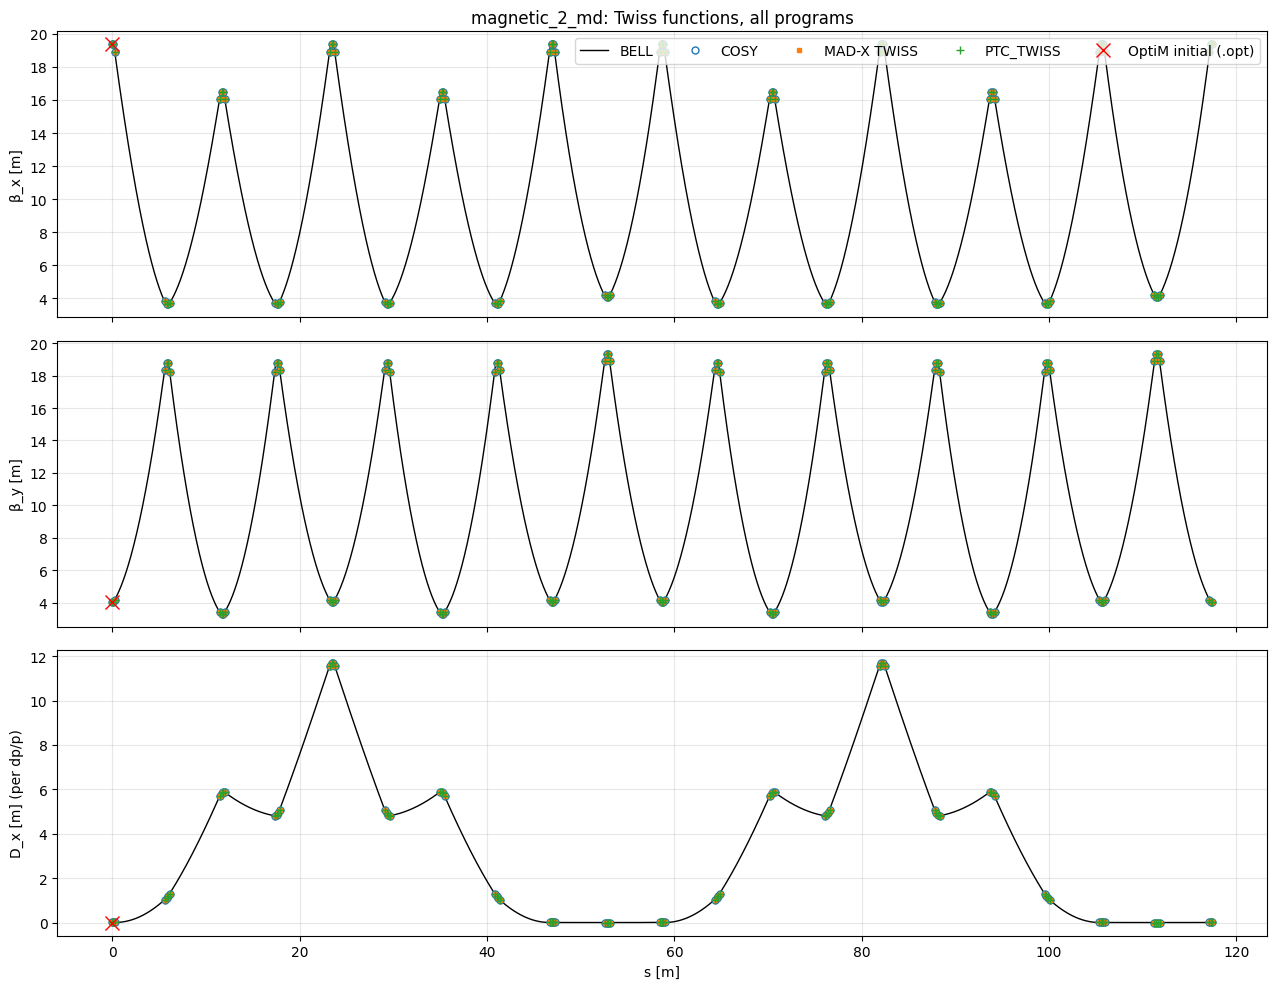

In [24]:
fig, ax = plt.subplots(3, 1, figsize=(13, 10), sharex=True)
for a, (col_b, col_c, col_m, col_p, lab) in zip(ax, [("betx_m","betx","BETX","BETA11","β_x [m]"), ("bety_m","bety","BETY","BETA22","β_y [m]"), ("Dx_m","dx","DXp","DISP1","D_x [m] (per dp/p)")]):
    a.plot(bt.s_m, bt[col_b], "k-", lw=1, label="BELL")
    a.plot(ct.s, ct[col_c], "o", ms=5, mfc="none", label="COSY")
    a.plot(mt.S, mt[col_m], "s", ms=3, label="MAD-X TWISS")
    a.plot(pt.S, pt[col_p], "+", ms=6, label="PTC_TWISS")
    a.set_ylabel(lab); a.grid(alpha=.3)
ax[0].plot([0], [19.3675], "rx", ms=10, label="OptiM initial (.opt)"); ax[1].plot([0], [4.05447], "rx", ms=10); ax[2].plot([0], [0.0], "rx", ms=10)
ax[0].legend(ncol=5); ax[2].set_xlabel("s [m]"); ax[0].set_title("magnetic_2_md: Twiss functions, all programs"); plt.tight_layout(); plt.show()

### Рис. 2. Разности относительно MAD-X TWISS (в точках MAD-X, концы элементов)
BELL интерполирован линейно на s MAD-X (точки MAD-X совпадают с границами элементов BELL); COSY и PTC также интерполированы по s (их точки — те же концы элементов, поэтому интерполяция фактически не нужна, кроме совпадающих s у маркеров).

lengths: MAD-X 86 COSY 85 PTC 86


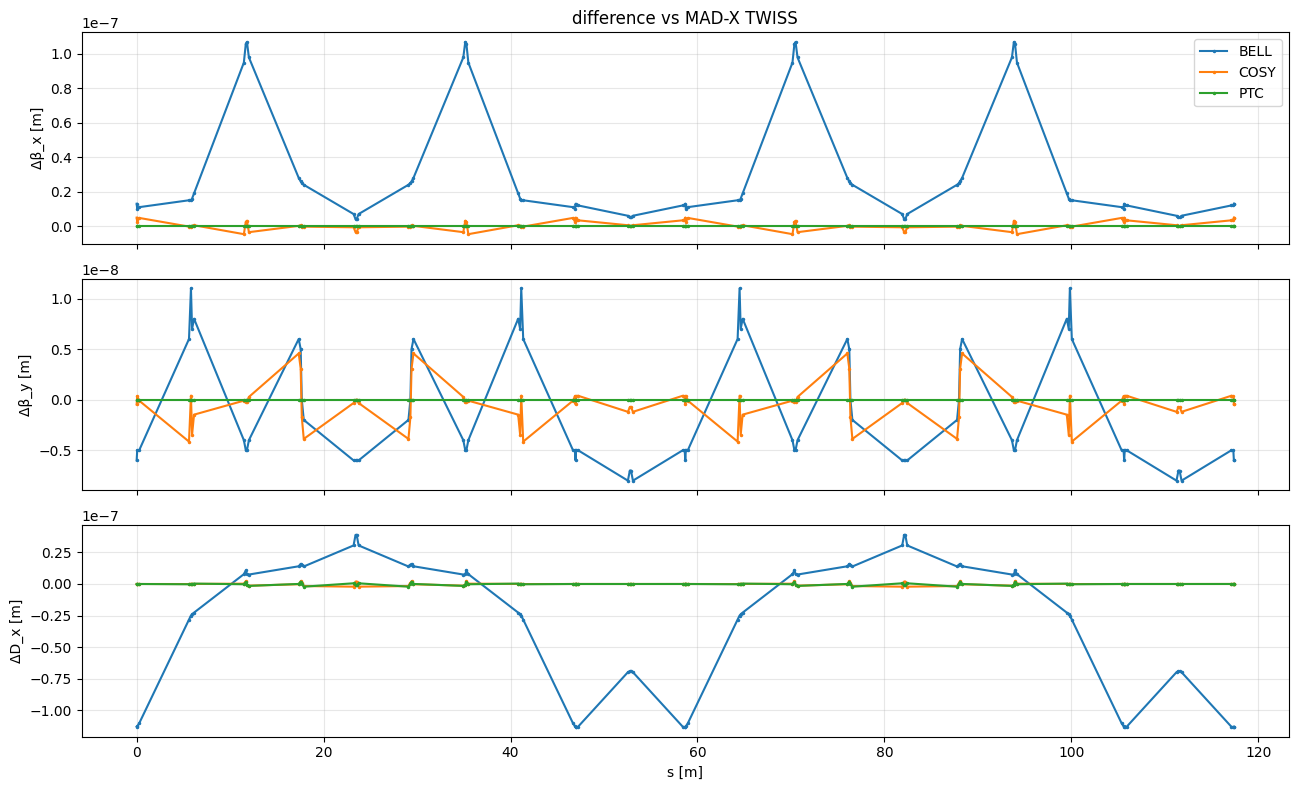

,program,max|Δβx| [m],max|Δβy| [m],max|ΔDx| [m],max rel Δβx,max rel Δβy
0,BELL,1.070000e-07,1.100000e-08,1.134460e-07,7.529469e-09,1.503864e-09
1,COSY,4.924040e-09,4.570616e-09,2.209222e-09,2.918911e-10,2.505445e-10
2,PTC,0.000000e+00,0.000000e+00,2.126931e-09,0.000000e+00,0.000000e+00


In [25]:
s = mt.S.values
def at(sx, y): return np.interp(s, sx, y)
cmp = {
 "BELL": (at(bt.s_m, bt.betx_m), at(bt.s_m, bt.bety_m), at(bt.s_m, bt.Dx_m)),
 "COSY": (at(ct.s, ct.betx), at(ct.s, ct.bety), at(ct.s, ct.dx)),
 "PTC":  (at(pt.S, pt.BETA11), at(pt.S, pt.BETA22), at(pt.S, pt.DISP1)),
}
ref = (mt.BETX.values, mt.BETY.values, mt.DXp.values)
print("lengths: MAD-X", len(s), "COSY", len(ct), "PTC", len(pt))
fig, ax = plt.subplots(3, 1, figsize=(13, 8), sharex=True); stat = []
for k, (bx, by, dx) in cmp.items():
    d = (bx-ref[0], by-ref[1], dx-ref[2])
    for a, dd, lab in zip(ax, d, ["Δβ_x [m]", "Δβ_y [m]", "ΔD_x [m]"]): a.plot(s, dd, ".-", ms=3, label=k); a.set_ylabel(lab); a.grid(alpha=.3)
    stat.append((k, *[np.max(np.abs(x)) for x in d], np.max(np.abs(d[0]/ref[0])), np.max(np.abs(d[1]/ref[1]))))
ax[0].legend(); ax[2].set_xlabel("s [m]"); ax[0].set_title("difference vs MAD-X TWISS"); plt.tight_layout(); plt.show()
pd.DataFrame(stat, columns=["program", "max|Δβx| [m]", "max|Δβy| [m]", "max|ΔDx| [m]", "max rel Δβx", "max rel Δβy"])

**Что следует:** если максимальные разности на уровне ~1e-6 м и меньше (округление вывода/шаг), то BELL, COSY, MAD-X и PTC
считают одно и то же кольцо с одной и той же линейной оптикой; расхождение ξy не связано с геометрией или фокусировкой,
а только с моделью края диполя. OptiM: совпадение βx0 = 19.3675 м, βy0 = 4.05447 м с периодическими значениями (19.36752, 4.05447) подтверждает ту же
оптику в начале кольца; полной таблицы OptiM нет (см. выше).

## 8. Почему ξy: OptiM/MAD-X = −1.817, а BELL/COSY = −2.2255

### Гамильтониан секторного магнита (поле B0 однородно, h = 1/ρ0, δ = dp/p, канонические x, p_x, y, p_y)
$$H = -(1+hx)\sqrt{(1+\delta)^2-p_x^2-p_y^2} + hx + \tfrac12 h^2x^2 .$$
Разложение до 3-го порядка по (x, p, δ):
$$H \approx -(1+\delta)(1+hx) + \frac{(1+hx)(p_x^2+p_y^2)}{2(1+\delta)} + hx + \tfrac12h^2x^2 .$$
* $-(1+\delta)hx + hx = -hx\delta$ — источник дисперсии.
* $\frac{p^2}{2(1+\delta)} \approx \frac{p^2}{2} - \delta\frac{p^2}{2}$ — «обычная» хроматичность (как в дрейфах и квадруполях).
  Так как $\oint\gamma\,ds = \oint K\beta\,ds$ для периодических функций, это даёт член **A** $= -\frac1{4\pi}\oint\gamma\,ds = -\frac1{4\pi}\oint K\beta\,ds$.
  Член $\tfrac12h^2x^2$ — от векторного потенциала, от δ не зависит (в канонических переменных).
* $\frac{hx\,p^2}{2}$ на дисперсионной орбите $x = D\delta + x_\beta$, $p_x = D'\delta + p_\beta$ даёт
  $\delta\big[\tfrac12 hD\,p_{x\beta}^2 + hD'\,x_\beta p_{x\beta} + \tfrac12 hD\,p_{y\beta}^2\big]$.
  Усреднение по фазе: $\langle p^2\rangle = \gamma J$, $\langle xp\rangle = -\alpha J$, $\Delta Q = \frac1{2\pi}\oint\partial\langle H_1\rangle/\partial J$:
  **C** $= +\frac1{4\pi}\int hD\gamma\,ds$ (x и y), **E** $= -\frac1{2\pi}\int hD'\alpha_x\,ds$ (только x).

### Жёсткий край при нулевом угле входа (тело это не содержит)
Поле $B_y = B_0\Theta(s)$ с плоской границей ⊥ орбите. Из $\nabla\times B = 0$: $\partial B_s/\partial y = \partial B_y/\partial s$ ⇒ $B_s = yB_0\delta_D(s)$.
Сила $F_y = q(v_sB_x - v_xB_s) = -q v_x y B_0\delta_D(s)$ ⇒ на входе $\Delta p_y = -h\,x'\,y$, на выходе $\Delta p_y = +h\,x'\,y$
($x' = p_x/p_s$). Это обычная краевая фокусировка $-h\tan e\,y$ с эффективным углом $e = x'$: частица на дисперсионной
орбите ($x' = D'\delta$) входит в магнит под углом. Тонкая линза $k = \pm hD'\delta$ ⇒
**F** $= +\frac{h}{4\pi}\sum_{BM}\big[\beta_yD'\big|_{in} - \beta_yD'\big|_{out}\big]$. По x: $F_x = q(v_yB_s - \dots)$ ∝ $y'y$ — не хроматично, поэтому ξx совпадает везде.

### Численно (оптика из линейных матриц, 400 срезов на диполь; D — на dp/p)

In [26]:
import subprocess, sys
src("analysis/chrom_terms.py", "python")
print(subprocess.run([sys.executable, str(R/"analysis/chrom_terms.py")], capture_output=True, text=True, encoding="utf-8").stdout)

C:\GIT_REPOS\SCT_2\chromaticity\analysis\chrom_terms.py  (lines 1-48)


import numpy as np
Br=3.47568504; L=5.3294148; h=np.radians(22.5)/L
k={'QF':1.81168058/Br,'QD':-2.01793283/Br,'QF1':1.93455213/Br,'QD1':-1.93455213/Br}
arc="OS2 QF BM QD OS1 QD BM QF SF2 QF BM QD SD QD BM QF SF1 QF BM QD SD QD BM QF SF2 QF BM QD OS1 QD BM QF OS2".split()
st="OS2 QF1 OBM QD1 OS1 QD1 OBM QF1 OS2".split(); seq=arc+st+arc+st
Ls={'BM':L,'OBM':L,'OS1':.12,'OS2':.06,'SF1':.12,'SF2':.12,'SD':.12,'QF':.21,'QD':.21,'QF1':.21,'QD1':.21}
def m2(K,l):
    if abs(K)<1e-15: return np.array([[1,l],[0,1.]])
    if K>0: s=np.sqrt(K); return np.array([[np.cos(s*l),np.sin(s*l)/s],[-s*np.sin(s*l),np.cos(s*l)]])
    s=np.sqrt(-K); return np.array([[np.cosh(s*l),np.sinh(s*l)/s],[s*np.sinh(s*l),np.cosh(s*l)]])
steps=[]
for e in seq:
    n=400 if e=='BM' else 20; hh=h if e=='BM' else 0.
    for i in range(n):
        ds=Ls[e]/n; Kx=k.get(e,0)+hh*hh; Ky=-k.get(e,0)
        A=np.eye(3); A[:2,:2]=m2(Kx,ds)
        if hh: A[0,2]=(1-np.cos(hh*ds))/hh; A[1,2]=np.sin(hh*ds)
        steps.append((e,i,n,A,m2(Ky,ds),hh,ds,Kx,Ky))
Mx=np.eye(3); My=np.eye(2)
for s in steps: Mx=s[3]@Mx; My=s[4]@My
D=np.linalg.solve(np.eye(2)-Mx[:2,:2],Mx[:2,2])
def tw(M): c=(M[0,0]+M[1,1])/2; sn=np.sign(M[0,1])*np.sqrt(1-c*c); return M[0,1]/sn,(M[0,0]-M[1,1])/(2*sn)
bx,ax=tw(Mx[:2,:2]); by,ay=tw(My)
Bx=np.array([[bx,-ax],[-ax,(1+ax*ax)/bx]]); By=np.array([[by,-ay],[-ay,(1+ay*ay)/by]]); d=np.array([D[0],D[1],1.])
T={k_:0.0 for k_ in ["quad_x","quad_y","h2bx","hDgx","hDpax","hDgy","edge_y"]}
for e,i,n,A,B,hh,ds,Kx,Ky in steps:
    if e=='BM' and i==0: T["edge_y"]+=h*By[0,0]*d[1]
    Bx2=A[:2,:2]@Bx@A[:2,:2].T; By2=B@By@B.T; d2=A@d
    av=lambda a,b:(a+b)/2
    bxm,axm,gxm=av(Bx[0,0],Bx2[0,0]),-av(Bx[0,1],Bx2[0,1]),av(Bx[1,1],Bx2[1,1])
    bym,gym=av(By[0,0],By2[0,0]),av(By[1,1],By2[1,1]); Dm,Dpm=av(d[0],d2[0]),av(d[1],d2[1])
    T["quad_x"]+=bxm*Kx*ds; T["quad_y"]+=bym*Ky*ds
    T["h2bx"]+=hh*hh*bxm*ds; T["hDgx"]+=hh*Dm*gxm*ds; T["hDpax"]+=hh*Dpm*axm*ds; T["hDgy"]+=hh*Dm*gym*ds
    Bx,By,d=Bx2,By2,d2
    if e=='BM' and i==n-1: T["edge_y"]-=h*By[0,0]*d[1]
p=4*np.pi
xi_x_lin=-T["quad_x"]/p; xi_y_lin=-T["quad_y"]/p
cx=[("A  -(1/4π)∮β_x(K1+h²)ds  = -(1/4π)∮γ_x ds  [-δp_x²/2]",xi_x_lin),
    ("C  +(1/4π)∫hDγ_x ds  [(1+hx)p_x²/2 on dispersion orbit]",T["hDgx"]/p),
    ("E  -(1/2π)∫hD'α_x ds  [cross term h D'δ x_β p_β]",-2*T["hDpax"]/p)]
cy=[("A  -(1/4π)∮β_y(-K1)ds = -(1/4π)∮γ_y ds  [-δp_y²/2]",xi_y_lin),
    ("C  +(1/4π)∫hDγ_y ds  [(1+hx)p_y²/2 on dispersion orbit]",T["hDgy"]/p),
    ("F  +(h/4π)Σ[β_y D'|in - β_y D'|out]  [hard-edge B_s kick Δp_y=∓h x' y]",T["edge_y"]/p)]
RES={"x":cx,"y":cy}
print(f"D(0)={D[0]:.6e} D'(0)={D[1]:.6e} betx0={bx:.5f} bety0={by:.5f}")
for nm,cs in (("x",cx),("y",cy)):
    s=0
    for t_,v in cs: s+=v; print(f"  xi_{nm} {t_:80s} {v:+.6f}   running {s:+.6f}")

D(0)=1.109408e-02 D'(0)=-5.061645e-04 betx0=19.36752 bety0=4.05447
  xi_x A  -(1/4π)∮β_x(K1+h²)ds  = -(1/4π)∮γ_x ds  [-δp_x²/2]                            -2.813419   running -2.813419
  xi_x C  +(1/4π)∫hDγ_x ds  [(1+hx)p_x²/2 on dispersion orbit]                          +0.661457   running -2.151962
  xi_x E  -(1/2π)∫hD'α_x ds  [cross term h D'δ x_β p_β]                                 +0.690465   running -1.461497
  xi_y A  -(1/4π)∮β_y(-K1)ds = -(1/4π)∮γ_y ds  [-δp_y²/2]                               -2.932233   running -2.932233
  xi_y C  +(1/4π)∫hDγ_y ds  [(1+hx)p_y²/2 on dispersion orbit]                          +0.706793   running -2.225440
  xi_y F  +(h/4π)Σ[β_y D'|in - β_y D'|out]  [hard-edge B_s kick Δp_y=∓h x' y]           +0.408422   running -1.817018



### Численные проверки гипотез
* Python RK4 точного гамильтониана (`exact_hamiltonian_check.py`): только тело → ξy = −2.225485; + краевые удары $\Delta p_y=\mp h x' y$ → **−1.817063** (= MAD-X до 6 знаков). С обратным знаком ударов −2.634 (не совпадает).
* MAD-X (`../MADX/edge_tests.madx`): TWISS толстый SBEND −1.817060; PTC exact model 2, `fringe=false` −1.817063 (жёсткий край PTC всегда учитывает этот кинематический член);
  PTC `exact=false` −2.932 (без всех членов h: только A); MAKETHIN (тонкие диполи) −2.932 / −2.813 — тонкие удары теряют и тело C/E, и края F.

In [27]:
print(open(R/"MADX/output/edge_tests.txt").read()); print(open(R/"analysis/exact_hamiltonian_check.out").read())

T1 MAD-X TWISS thick SBEND (E1=E2=0)           DQ2_dp = -1.817060
T2 PTC exact model2 fringe=false                 DQ2_dp = -1.817063
T3 MAD-X TWISS after MAKETHIN (thin bends)       Q2 = 2.461337 DQ2_dp = -2.932272
                                                 DQ1_dp = -2.813470

Q0 [0.46172015 0.46133732]
xi (dQ/d(dp/p)) [-1.46153562 -2.22548499]
EDGE sign +1: Q0 [0.46172015 0.46133732] xi [-1.46153562 -1.81706334]



### Вывод
| член | ξx | ξy | BELL / COSY FR 0 | OptiM / MAD-X / PTC |
|---|---|---|---|---|
| A: −(1/4π)∮γ ds | −2.8134 | −2.9322 | да | да |
| C: (1/4π)∫hDγ ds | +0.6615 | +0.7068 | да | да |
| E: −(1/2π)∫hD'α_x ds | +0.6905 | — | да | да |
| F: жёсткий край, Δp_y = ∓h x' y | 0 | +0.4084 | **нет** | да |
| сумма | −1.4615 | −2.2254 / −1.8170 | | |

* **Доказано:** разница +0.408 — ровно член F (аналитически 0.40842, численно в RK4 −2.225485 → −1.817063, совпадает с MAD-X/PTC до 1e-6).
  Он следует из уравнений Максвелла для поля с резкой границей (B_s на краю) и присутствует в любом реальном магните с краем,
  даже при нулевом угле входа.
* **Физически правильно** для секторного магнита с жёстким краем: **ξy = −1.817** (OptiM, MAD-X, PTC).
  BELL и COSY с `FR 0` считают только тело магнита (поле без края, не удовлетворяющее Максвеллу на границе), поэтому −2.2255.
  BELL и COSY действительно согласуются между собой, но в модели «без краёв».
* **Не проверено:** реализация полной матрицы TRANSPORT 2-го порядка (Brown) не делалась — член F проверен прямым выводом и RK4;
  BELL с добавленным краевым отображением не запускался (ядро BELL не меняли); COSY FR 1/2 не запускается (нет SYSCA.DAT),
  поэтому что именно COSY включает в FR 1–3 — не проверено. С конечным fringe (FINT, HGAP ≠ 0) добавятся ещё члены.

## 9. Краевые поля в COSY: FR 3 (и FR 1, FR 2) — проверка гипотезы «жёсткого края»

**SYSCA.DAT.** На машине его не было (поиск по всем дискам: только `C:\Program Files\COSY 10.2` без него).
По Beam Physics Manual 10.2 (разд. 3.3.7) SYSCA.DAT нужен только для FR 2 (FR 3 и FR 2.5 интегрируют напрямую),
а создаётся штатной процедурой `CRSYSCA` из `cosy.fox` («This procedure produces the file SYSCA.DAT, which is shipped with the code»).
Запустили её как чёрный ящик: `COSY/sysca/mk_sysca.fox` → `SYSCA.DAT` (295 кБ, ~10 мин; предупреждения RK «minimum stepsize» и POTI error norm 3e-4).
Практически COSY 10.2 читает SYSCA.DAT и при FR 1 (без файла FR 1 падал), поэтому FR 1 тоже стал доступен только после этого.
Альтернатива — официальный SYSCA.DAT с сайта загрузки COSY INFINITY (bmtdynamics.org).

**Как устроено.** `lattice_md_fr.fox` — то же кольцо, но `RINGFR FD FQ GD`: `FR FD` перед каждым `MS`, `FR FQ` для квадруполей/секступолей,
`GD` — апертура диполя (масштаб функции Энге). (a) FR 3 только на диполях; (b) FR 3 на всём кольце; плюс FR 1, FR 2 и FR 3 только на квадруполях.
Каждый случай считается двумя способами: OV 3 2 1 + TP (`ov321_fr.fox`) и OV 3 3 0 → карта → замкнутая орбита при ±δK → след (`ov330_fr.fox` + `fr_analysis.py`).

In [28]:
src("COSY/lattice_md_fr.fox", "pascal"); src("COSY/ov321_fr.fox", "pascal"); src("COSY/ov330_fr.fox", "pascal")
src("COSY/fr_analysis.py", "python"); src("COSY/sysca/mk_sysca.fox", "pascal")

C:\GIT_REPOS\SCT_2\chromaticity\COSY\lattice_md_fr.fox  (lines 1-21)


{ lattice_md_fr.fox - same ring as lattice_md.fox, but fringe mode set per element type -> lattice_md_fr.bin }
INCLUDE 'lattice_md';                                  { gives PART }
PROCEDURE RINGFR FD FQ GD;                             { FD/FQ = FR mode for dipoles / quads+sextupoles, GD = dipole aperture [m] (Enge extent) }
  VARIABLE AP 1; VARIABLE LB 1; VARIABLE RB 1;
  PROCEDURE BM;  FR FD; MS RB 22.5 GD 0 0 0 0 0; FR FQ; ENDPROCEDURE;
  PROCEDURE QF;  MQ 0.21  1.81168058*AP AP; ENDPROCEDURE;
  PROCEDURE QD;  MQ 0.21 -2.01793283*AP AP; ENDPROCEDURE;
  PROCEDURE QF1; MQ 0.21  1.93455213*AP AP; ENDPROCEDURE;
  PROCEDURE QD1; MQ 0.21 -1.93455213*AP AP; ENDPROCEDURE;
  PROCEDURE SX;  MH 0.12 0 AP; ENDPROCEDURE;
  PROCEDURE ARC;
    DL 0.06; QF; BM; QD; DL 0.12; QD; BM; QF; SX;
    QF; BM; QD; SX; QD; BM; QF; SX;
    QF; BM; QD; SX; QD; BM; QF; SX;
    QF; BM; QD; DL 0.12; QD; BM; QF; DL 0.06;
  ENDPROCEDURE;
  PROCEDURE STR; DL 0.06; QF1; DL LB; QD1; DL 0.12; QD1; DL LB; QF1; DL 0.06; ENDPROCEDURE;
  AP := 0.05; LB := 5.3294148; RB := LB/(22.5*PI/180);
  FR FQ; UM; ARC; STR; ARC; STR;
ENDPROCEDURE;
SAVE 'lattice_md_fr';

C:\GIT_REPOS\SCT_2\chromaticity\COSY\ov321_fr.fox  (lines 1-18)


{ ov321_fr.fox - xi by OV 3 2 1 + TP with fringe fields. Usage: cases chosen by CASE list below }
INCLUDE 'lattice_md_fr';
PROCEDURE RUN;
  VARIABLE MU 1000 2; VARIABLE G 1; VARIABLE F 1; VARIABLE I 1; VARIABLE KD 1 12; VARIABLE KQ 1 12; VARIABLE KG 1 12;
  OV 3 2 1;
  KD(1):=0; KQ(1):=0; KG(1):=0.05;   KD(2):=3; KQ(2):=0; KG(2):=0.05;   KD(3):=3; KQ(3):=3; KG(3):=0.05;
  KD(4):=0; KQ(4):=3; KG(4):=0.05;   KD(5):=3; KQ(5):=0; KG(5):=0.025;  KD(6):=3; KQ(6):=0; KG(6):=0.0125;
  KD(7):=3; KQ(7):=0; KG(7):=0.00625;  { FR 1 / FR 2 need SYSCA.DAT in the working dir: made by sysca\mk_sysca.fox (CRSYSCA) }
  KD(8):=1; KQ(8):=0; KG(8):=0.05;   KD(9):=1; KQ(9):=1; KG(9):=0.05;   KD(10):=2; KQ(10):=0; KG(10):=0.05;  KD(11):=2; KQ(11):=2; KG(11):=0.05;
  G := 1+270/1875.612945; F := 1+1/G;
  OPENF 20 'output/cosy_ov321_fr.txt' 'UNKNOWN';
  LOOP I 1 11;
    PART 270*PARA(1); RINGFR KD(I) KQ(I) KG(I); TP MU;
    WRITE 20 'FD '&ST(KD(I))&' FQ '&ST(KQ(I))&' GAP '&ST(KG(I)) 'Qx '&ST(CONS(MU(1)))&' Qy '&ST(CONS(MU(2))) 'xi_x '&ST(F*(MU(1)|(0&0&0&0&1)))&' xi_y '&ST(F*(MU(2)|(0&0&0&0&1)));
  ENDLOOP;
  CLOSEF 20;
ENDPROCEDURE;
RUN; END;

C:\GIT_REPOS\SCT_2\chromaticity\COSY\ov330_fr.fox  (lines 1-19)


{ ov330_fr.fox - full 6D map (OV 3 3 0) with fringe fields, dumped per case for fr_analysis.py (closed-orbit method) }
INCLUDE 'lattice_md_fr';
PROCEDURE RUN;
  VARIABLE I 1; VARIABLE KD 1 12; VARIABLE KQ 1 12; VARIABLE KG 1 12;
  OV 3 3 0;
  KD(1):=0; KQ(1):=0; KG(1):=0.05;   KD(2):=3; KQ(2):=0; KG(2):=0.05;   KD(3):=3; KQ(3):=3; KG(3):=0.05;
  KD(4):=0; KQ(4):=3; KG(4):=0.05;   KD(5):=3; KQ(5):=0; KG(5):=0.025;  KD(6):=3; KQ(6):=0; KG(6):=0.0125;
  KD(7):=3; KQ(7):=0; KG(7):=0.00625;  { FR 1 / FR 2 need SYSCA.DAT in the working dir: made by sysca\mk_sysca.fox (CRSYSCA) }
  KD(8):=1; KQ(8):=0; KG(8):=0.05;   KD(9):=1; KQ(9):=1; KG(9):=0.05;   KD(10):=2; KQ(10):=0; KG(10):=0.05;  KD(11):=2; KQ(11):=2; KG(11):=0.05;
  OPENF 31 'output/map_ov330_fr.txt' 'UNKNOWN';
  LOOP I 1 11;
    PART 270; RINGFR KD(I) KQ(I) KG(I);
    WRITE 31 'CASE '&ST(KD(I))&' '&ST(KQ(I))&' '&ST(KG(I));
    WRITE 31 'GAMMA0 '&ST(1+270/1875.612945); WRITE 31 'LENGTH '&ST(SPOS);
    WRITE 31 MAP(1) MAP(2) MAP(3) MAP(4) MAP(5) MAP(6);
  ENDLOOP;
  CLOSEF 31;
ENDPROCEDURE;
RUN; END;

C:\GIT_REPOS\SCT_2\chromaticity\COSY\fr_analysis.py  (lines 1-50)


"""fr_analysis.py - chromaticity from OV 3 3 0 maps with fringe fields (closed-orbit method), compared with OV 3 2 1 TP.
Reads output/map_ov330_fr.txt (several CASE blocks) and output/cosy_ov321_fr.txt."""
import numpy as np, pathlib, re, json
P = pathlib.Path(__file__).parent/"output"
def parse_maps(fn):
    blocks, cur = [], None
    for l in (P/fn).read_text().splitlines():
        s = l.split()
        if not s: continue
        if s[0] == "CASE": cur = dict(case=tuple(float(v) for v in s[1:4]), maps=[]); blocks.append(cur); continue
        if s[0] == "GAMMA0": cur["g"] = float(s[1]); continue
        if s[0] == "LENGTH": cur["C"] = float(s[1]); continue
        if s[0] == "I": cur["maps"].append({}); continue
        if l.strip().startswith("---"): continue
        if len(s) >= 9: cur["maps"][-1][tuple(map(int, s[3:9]))] = float(s[1])
    return blocks
def xi_closed_orbit(b, h=1e-4):
    maps, F = b["maps"], 1+1/b["g"]
    def T(z, d):
        v = [z[0], z[1], z[2], z[3], 0.0, d]
        return np.array([sum(c*np.prod([v[k]**e[k] for k in range(6)]) for e, c in maps[i].items()) for i in range(4)])
    def J(z, d, e=1e-7):
        return np.array([(T(z+e*np.eye(4)[k], d)-T(z-e*np.eye(4)[k], d))/(2*e) for k in range(4)]).T
    def co(d):
        z = np.zeros(4)
        for _ in range(50):
            dz = np.linalg.solve(np.eye(4)-J(z, d), T(z, d)-z); z = z+dz
            if np.max(abs(dz)) < 1e-16: break
        return z
    def tune(m):
        c = (m[0,0]+m[1,1])/2; return np.arccos(c)/(2*np.pi) if m[0,1] > 0 else 1-np.arccos(c)/(2*np.pi)
    q = []
    for d in (-h, 0.0, h):
        m = J(co(d), d); q.append((tune(m[:2,:2]), tune(m[2:,2:])))
    return dict(Qx=q[1][0], Qy=q[1][1], xi_x=F*(q[2][0]-q[0][0])/(2*h), xi_y=F*(q[2][1]-q[0][1])/(2*h))
def parse_tp(fn="cosy_ov321_fr.txt"):
    t = (P/fn).read_text().split()
    out = []
    for i, w in enumerate(t):
        if w == "FD": out.append(dict(FD=float(t[i+1]), FQ=float(t[i+3]), GAP=float(t[i+5]), Qx=float(t[i+7]), Qy=float(t[i+9]), xi_x=float(t[i+11]), xi_y=float(t[i+13])))
    return out
if __name__ == "__main__":
    tp = parse_tp(); rows = []
    for b, t in zip(parse_maps("map_ov330_fr.txt"), tp):
        r = xi_closed_orbit(b)
        rows.append(dict(FR_dip=int(b["case"][0]), FR_quad=int(b["case"][1]), gap_m=b["case"][2],
                         Qx_TP=t["Qx"], Qy_TP=t["Qy"], xi_x_TP321=t["xi_x"], xi_y_TP321=t["xi_y"],
                         Qx_CO330=r["Qx"], Qy_CO330=r["Qy"], xi_x_CO330=r["xi_x"], xi_y_CO330=r["xi_y"]))
    for r in rows: print(" ".join(f"{k}={v:.9g}" if isinstance(v, float) else f"{k}={v}" for k, v in r.items()))
    json.dump(rows, open(P/"fr_analysis.json", "w"), indent=1)

C:\GIT_REPOS\SCT_2\chromaticity\COSY\sysca\mk_sysca.fox  (lines 1-4)


{ mk_sysca.fox - generate SYSCA.DAT with COSY's own documented procedure CRSYSCA (Beam Physics Manual 10.2, sec. 3.3.7) }
INCLUDE 'C:/GIT_REPOS/SCT_2/COSY/src/COSY';
PROCEDURE RUN; CRSYSCA; ENDPROCEDURE;
RUN; END;

In [29]:
sys.path.insert(0, str(R/"COSY")); import importlib, fr_analysis; importlib.reload(fr_analysis)
subprocess.run([sys.executable, str(R/"COSY/fr_analysis.py")], check=True, capture_output=True)
fr = pd.DataFrame(json.load(open(R/"COSY/output/fr_analysis.json")))
fr["dxi_x(330-321)"] = fr.xi_x_CO330-fr.xi_x_TP321; fr["dxi_y(330-321)"] = fr.xi_y_CO330-fr.xi_y_TP321
pd.set_option("display.float_format", "{:.6f}".format); pd.set_option("display.width", 250)
fr[["FR_dip","FR_quad","gap_m","Qx_TP","Qy_TP","xi_x_TP321","xi_x_CO330","xi_y_TP321","xi_y_CO330","dxi_x(330-321)","dxi_y(330-321)"]]

,FR_dip,FR_quad,gap_m,Qx_TP,Qy_TP,xi_x_TP321,xi_x_CO330,xi_y_TP321,xi_y_CO330,dxi_x(330-321),dxi_y(330-321)
0,0,0,0.050000,0.461720,0.461337,-1.461536,-1.461536,-2.225485,-2.225486,-0.000001,-0.000001
1,3,0,0.050000,0.461720,0.455729,-1.461498,-1.461499,-1.807670,-1.807671,-0.000001,-0.000001
2,3,3,0.050000,0.458572,0.452122,-1.452590,-1.452596,-1.796928,-1.796931,-0.000006,-0.000004
3,0,3,0.050000,0.458571,0.457732,-1.452627,-1.452633,-2.216842,-2.216847,-0.000006,-0.000005
4,3,0,0.025000,0.461720,0.458525,-1.461526,-1.461527,-1.812336,-1.812337,-0.000001,-0.000001
5,3,0,0.012500,0.461720,0.459929,-1.461533,-1.461534,-1.814692,-1.814692,-0.000001,-0.000001
6,3,0,0.006250,0.461720,0.460633,-1.461535,-1.461536,-1.815876,-1.815876,-0.000001,-0.000001
7,1,0,0.050000,0.461718,0.455728,-1.461505,-1.461497,-1.807680,-1.807675,0.000008,0.000005
8,1,1,0.050000,0.458568,0.452118,-1.452594,-1.452590,-1.796935,-1.796932,0.000005,0.000003
9,2,0,0.050000,0.461718,0.455728,-1.461505,-1.461497,-1.807680,-1.807675,0.000008,0.000005


### 9a. Сходимость FR 3 (только диполи) к жёсткому краю при апертуре → 0
Функция Энге масштабируется апертурой D; при D→0 край становится жёстким, и ξy должен стремиться к MAD-X/PTC (−1.817063).

linear fit xi_y(gap) = -1.817037 + 0.1875*gap  -> extrapolated hard edge xi_y(0) = -1.817037;  MAD-X = -1.817063;  body only (FR 0) = -2.225485
Qy(gap) -> 0.461330 at gap=0;  FR 0: 0.461337;  MAD-X Qy_frac = 0.461337


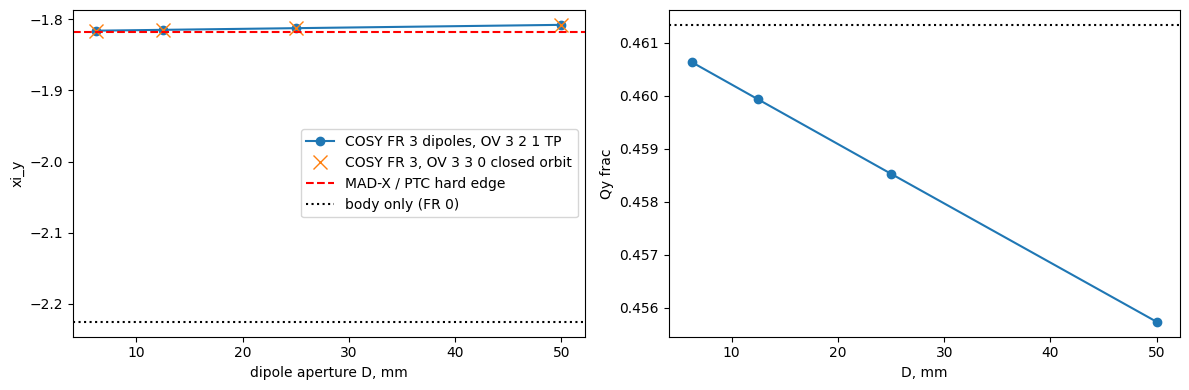

In [30]:
g = fr[(fr.FR_dip==3)&(fr.FR_quad==0)].sort_values("gap_m")
k = np.polyfit(g.gap_m, g.xi_y_TP321, 1); print(f"linear fit xi_y(gap) = {k[1]:.6f} + {k[0]:.4f}*gap  -> extrapolated hard edge xi_y(0) = {k[1]:.6f};  MAD-X = -1.817063;  body only (FR 0) = -2.225485")
k2 = np.polyfit(g.gap_m, g.Qy_TP, 1); print(f"Qy(gap) -> {k2[1]:.6f} at gap=0;  FR 0: 0.461337;  MAD-X Qy_frac = {mp['Q2']-2:.6f}")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(g.gap_m*1e3, g.xi_y_TP321, "o-", label="COSY FR 3 dipoles, OV 3 2 1 TP")
ax[0].plot(g.gap_m*1e3, g.xi_y_CO330, "x", ms=10, label="COSY FR 3, OV 3 3 0 closed orbit")
ax[0].axhline(-1.817063, c="r", ls="--", label="MAD-X / PTC hard edge"); ax[0].axhline(-2.225485, c="k", ls=":", label="body only (FR 0)")
ax[0].set_xlabel("dipole aperture D, mm"); ax[0].set_ylabel("xi_y"); ax[0].legend()
ax[1].plot(g.gap_m*1e3, g.Qy_TP, "o-"); ax[1].axhline(0.461337, c="k", ls=":"); ax[1].set_xlabel("D, mm"); ax[1].set_ylabel("Qy frac")
plt.tight_layout(); plt.show()

### 9b. Выводы по краевым полям
* FR 3 на диполях: ξy = −2.2255 → **−1.8077** (D = 50 мм), ξx почти не меняется (−1.46150). При D → 0 ξy → −1.8171 = MAD-X/PTC.
  Гипотеза подтверждена: разница BELL/COSY-FR0 и OptiM/MAD-X — краевой член диполя Δp_y = ∓h x′ y (в FR 0 COSY его нет), а не ошибка программ.
* Конечный край (D = 50 мм) ещё и уменьшает Qy (0.46134 → 0.45573: вертикальная фокусировка краевого поля ~ D·h²) — у жёсткого края её нет; отсюда же малая разница ξy с MAD-X (0.009 при D=50 мм, линейно по D).
* FR 3 на квадруполях: Qx,y падают на ~0.003, ξ меняется на ~0.009 (x и y) — эффект размазанного градиента, к гипотезе не относится.
* FR 1 ≈ FR 2 на диполях (одинаково, т.к. для `MS` FR 2 берёт ту же процедуру) совпадают с FR 3 до 1e-5; FR 1/2 на всём кольце — до 4e-5.
* **OV 3 3 0 и OV 3 2 1 дают одну и ту же хроматичность** (FR 0 и FR 3): разница ≤ 6e-6 — это ошибка конечной разности ±δK в методе замкнутой орбиты (3-й порядок карты), не физика.
  OV 3 3 0 сам по себе считается без проблем (и с FR 3); не работает только `TP` на 6D-карте без ВЧ (жорданов блок l–δ, нет продольной нормальной формы).

## 10. 6D-карта с ВЧ (OV 3 3 0): можно ли достать линейную ξ? TS и метод неподвижной точки
1. **COSY `TS`** (нормальная форма) на OV 3 3 0 + тонкий резонатор: сдвиги частот от амплитуд (r_x², r_s², r_y²).
2. **OV 3 3 1 c `PART 270*PARA(1)`**: в 6D энергия уже переменная, параметр в карту не попадает (все коэффициенты по PARA = 0) → TP/TS дают ξ = 0. Не работает.
3. **Метод неподвижной точки** (Python, `rf_ts_analysis.py`): кольцевая карта COSY OV 3 3 0 + свой тонкий ВЧ-удар + постоянный сдвиг фазы за оборот Δl
   (= смещение частоты ВЧ) → неподвижная точка с δ* ≠ 0; Q — собственные частоты 6×6 якобиана; ξ = dQ/dδ*.

In [31]:
src("COSY/rf_ts.fox", "pascal"); src("COSY/rf_ts_analysis.py", "python")
subprocess.run([sys.executable, str(R/"COSY/rf_ts_analysis.py")], check=True, capture_output=True, cwd=R/"COSY")
rr = json.load(open(R/"COSY/output/rf_ts_analysis.json"))
print(open(R/"COSY/output/rf_ts_ov331.txt").read()[:600])

C:\GIT_REPOS\SCT_2\chromaticity\COSY\rf_ts.fox  (lines 1-29)


{ rf_ts.fox - 6D map with thin RF: can linear xi be recovered? (a) OV 3 3 0 + TP/TS, (b) OV 3 3 1 with energy parameter + TP/TS }
INCLUDE 'lattice_md';
PROCEDURE RUN;
  VARIABLE MU 1000 3; VARIABLE VRF 1 1 1; VARIABLE FREQ 1; VARIABLE I 1; VARIABLE V 1 6; VARIABLE F 1;
  V(1) := 100; V(2) := 10; V(3) := 1; V(4) := 0.1; V(5) := 0.01; V(6) := 0.001;   { kV }
  OV 3 3 0;                                                                     { OV initialises CLIGHT etc. }
  FREQ := SQRT(1-1/SQR(1+270/1875.612945))*CLIGHT/117.388296;                   { h=1 }
  F := 1+1/(1+270/1875.612945);
  OPENF 33 'output/rf_ts_ov330.txt' 'UNKNOWN';
  FR 0;
  LOOP I 1 6;
    VRF(1,1) := V(I); PART 270; RING 0 0 0 0 0 0 0 0; RF VRF 0 FREQ 0 0.05;
    WRITE 33 '##### V_kV '&ST(V(I));
    TP MU; WRITE 33 '# TP' MU(1) MU(2) MU(3);
    TS MU; WRITE 33 '# TS' MU(1) MU(2) MU(3);
  ENDLOOP;
  CLOSEF 33;
  OPENF 34 'output/rf_ts_ov331.txt' 'UNKNOWN';
  OV 3 3 1; FR 0; FREQ := SQRT(1-1/SQR(1+270/1875.612945))*CLIGHT/117.388296;
  LOOP I 1 6;
    VRF(1,1) := V(I); PART 270*PARA(1); RING 0 0 0 0 0 0 0 0; RF VRF 0 FREQ 0 0.05;
    TP MU;
    WRITE 34 'TP V_kV '&ST(V(I))&' Qx '&ST(CONS(MU(1)))&' Qy '&ST(CONS(MU(2)))&' Qs '&ST(CONS(MU(3))) 'xi_x '&ST(F*(MU(1)|(0&0&0&0&0&0&1)))&' xi_y '&ST(F*(MU(2)|(0&0&0&0&0&0&1)));
    TS MU;
    WRITE 34 'TS V_kV '&ST(V(I))&' Qx '&ST(CONS(MU(1)))&' Qy '&ST(CONS(MU(2)))&' Qs '&ST(CONS(MU(3))) 'xi_x '&ST(F*(MU(1)|(0&0&0&0&0&0&1)))&' xi_y '&ST(F*(MU(2)|(0&0&0&0&0&0&1)));
  ENDLOOP;
  CLOSEF 34;
ENDPROCEDURE;
RUN; END;

C:\GIT_REPOS\SCT_2\chromaticity\COSY\rf_ts_analysis.py  (lines 1-75)


"""rf_ts_analysis.py - can linear chromaticity be recovered from a 6D map with RF?
(1) COSY TS (normal form) on OV 3 3 0 + thin RF: dQx,y/d(r_s^2) vs V   [output/rf_ts_ov330.txt]
(2) Fixed-point method in Python: COSY OV 3 3 0 ring map (FR 0 and FR 3 dipoles) + own thin RF kick
    + constant per-turn phase slip dl (= RF frequency offset) -> off-momentum fixed point delta*(dl);
    tunes = eigen-tunes of the 6x6 Jacobian there; xi = dQ/d delta* -> compare with OV 3 2 1 as V -> 0."""
import re, json, pathlib, numpy as np
from fr_analysis import parse_maps
P = pathlib.Path(__file__).parent/"output"
res = {}
# ---------- (1) TS coefficients
t = (P/"rf_ts_ov330.txt").read_text()
ts = []
for blk in t.split("#####")[1:]:
    V = float(blk.split()[1]); body = blk.split("# TS")[1]
    first = body.split("---")[0]
    c = {tuple(map(int, e.split())): float(v) for v, e in re.findall(r"^\s+\d+\s+(\S+)\s+\d+\s+((?:\d+\s+){5}\d+)\s*$", first, re.M)}
    ts.append(dict(V_kV=V, Qx=c.get((0,)*6), dQx_drx2=c.get((2,0,0,0,0,0)), dQx_drs2=c.get((0,0,2,0,0,0)), dQx_dry2=c.get((0,0,0,0,2,0)),
                   ok=len(c) > 1))
res["TS"] = ts
# ---------- (2) fixed point with RF
def load(case):
    for b in parse_maps("map_ov330_fr.txt"):
        if b["case"][:2] == case and abs(b["case"][2]-0.05) < 1e-9: return b
def make(b):
    maps = b["maps"]; F = 1+1/b["g"]; C = b["C"]
    def ring(v):
        return np.array([sum(c*np.prod([v[k]**e[k] for k in range(6)]) for e, c in maps[i].items()) for i in range(6)])
    return ring, F, C
def rf_map(ring, C, V_kV, dl, sign):
    k = 2*np.pi/C; a = sign*V_kV*1e-3/270.0           # thin cavity, h=1: dK/K kick = a sin(k l)
    def M(v):
        w = ring(v); w[4] = w[4]+dl; w[5] = w[5]+a*np.sin(k*w[4]); return w
    return M
def jac(M, z, e=1e-7):
    return np.array([(M(z+e*np.eye(6)[i])-M(z-e*np.eye(6)[i]))/(2*e) for i in range(6)]).T
def fixed_point(M, z0):
    z = z0.copy()
    for _ in range(60):
        dz = np.linalg.solve(np.eye(6)-jac(M, z), M(z)-z); z = z+dz
        if np.max(abs(dz)) < 1e-15: break
    return z
def tunes(J):
    ev = np.linalg.eigvals(J); q = np.sort(np.abs(np.angle(ev[ev.imag > 0]))/(2*np.pi))
    return q, ev
def scan(case, Vs, h=2e-5):
    ring, F, C = make(load(case)); out = []
    for V in Vs:
        sign = None
        for s in (+1, -1):                             # choose the stable RF sign
            q, ev = tunes(jac(rf_map(ring, C, V, 0.0, s), np.zeros(6)))
            if np.all(abs(abs(ev)-1) < 1e-6) and len(q) == 3: sign = s; break
        rows = []
        for d in (-h, 0.0, h):                        # d = target fixed-point dK; dl from linear slip estimate, then solved
            M0 = rf_map(ring, C, V, 0.0, sign)
            # find dl such that fixed point has dK = d: dl = -(l(fixed transverse orbit, dK=d)) per turn
            lam = lambda dl: fixed_point(rf_map(ring, C, V, dl, sign), np.array([0,0,0,0,0,d]))
            dl = -17.8*d
            for _ in range(20):
                z = lam(dl); g = z[5]-d
                z2 = lam(dl+1e-9); dg = (z2[5]-z[5])/1e-9
                dl -= g/dg
                if abs(g) < 1e-14: break
            z = lam(dl); q, _ = tunes(jac(rf_map(ring, C, V, dl, sign), z))
            rows.append((z[5], q))
        qs = rows[1][1]; dd = rows[2][0]-rows[0][0]
        dq = (rows[2][1]-rows[0][1])/dd*F
        out.append(dict(V_kV=V, sign=sign, Q_sorted=qs.tolist(), dQ_ddelta_p_sorted=dq.tolist()))
    return out
Vs = [100, 10, 1, 0.1, 0.01, 0.001]
for case, name in [((0.0, 0.0), "FR0"), ((3.0, 0.0), "FR3dip")]:
    res["fixed_point_"+name] = scan(case, Vs)
json.dump(res, open(P/"rf_ts_analysis.json", "w"), indent=1)
for k, v in res.items():
    print("==", k)
    for r in v: print("  ", r)

TP V_kV  100.0000000000000 Qx 0.4617201483852674 Qy 0.4097138126850692E-002 Qs 0.4613373212771318
xi_x  0.000000000000000 xi_y  0.000000000000000
TS V_kV  100.0000000000000 Qx 0.4617201483852674 Qy 0.4097138126850692E-002 Qs 0.4613373212771318
xi_x  0.000000000000000 xi_y  0.000000000000000
TP V_kV  10.00000000000000 Qx 0.4617201483766904 Qy 0.1295596640668595E-002 Qs 0.4613373212771318
xi_x  0.000000000000000 xi_y  0.000000000000000
TS V_kV  10.00000000000000 Qx 0.4617201483766904 Qy 0.1295596640668595E-002 Qs 0.4613373212771318
xi_x  0.000000000000000 xi_y  0.000000000000000
TP V_kV  1.00000


In [32]:
rows = []
for nm in ("FR0", "FR3dip"):
    for r in rr["fixed_point_"+nm]:
        q, d = r["Q_sorted"], r["dQ_ddelta_p_sorted"]
        rows.append(dict(lattice=nm, V_kV=r["V_kV"], Qs=q[0], Qy=q[1], Qx=q[2], xi_x_fixedpoint=d[2], xi_y_fixedpoint=d[1]))
fp = pd.DataFrame(rows)
ref = fr.set_index(["FR_dip","FR_quad","gap_m"])
fp["xi_x_OV321"] = np.where(fp.lattice=="FR0", ref.loc[(0,0,0.05),"xi_x_TP321"], ref.loc[(3,0,0.05),"xi_x_TP321"])
fp["xi_y_OV321"] = np.where(fp.lattice=="FR0", ref.loc[(0,0,0.05),"xi_y_TP321"], ref.loc[(3,0,0.05),"xi_y_TP321"])
fp["diff_x"] = fp.xi_x_fixedpoint-fp.xi_x_OV321; fp["diff_y"] = fp.xi_y_fixedpoint-fp.xi_y_OV321
pd.set_option("display.float_format", "{:.9g}".format); fp

,lattice,V_kV,Qs,Qy,Qx,xi_x_fixedpoint,xi_y_fixedpoint,xi_x_OV321,xi_y_OV321,diff_x,diff_y
0,FR0,100,0.00299275708,0.461337321,0.461720148,-1.46153573,-2.22548494,-1.46153571,-2.22548493,-2.06490092e-08,-8.04235878e-09
1,FR0,10,0.000946380338,0.461337321,0.461720148,-1.46153572,-2.22548494,-1.46153571,-2.22548493,-4.04472278e-09,-8.04495937e-09
2,FR0,1,0.000299271343,0.461337321,0.461720148,-1.46153572,-2.22548494,-1.46153571,-2.22548493,-2.38273379e-09,-8.04235878e-09
3,FR0,0.1,9.46378958e-05,0.461337321,0.461720148,-1.46153572,-2.22548494,-1.46153571,-2.22548493,-2.22147656e-09,-8.04495981e-09
4,FR0,0.01,2.99271299e-05,0.461337321,0.461720148,-1.46153572,-2.22548494,-1.46153571,-2.22548493,-2.20066898e-09,-8.04235833e-09
5,FR0,0.001,9.4637896e-06,0.461337321,0.461720148,-1.46153572,-2.22548494,-1.46153571,-2.22548493,-2.20327023e-09,-8.04235878e-09
6,FR3dip,100,0.00299272218,0.455729339,0.461720442,-1.46149827,-1.80767011,-1.46149825,-1.8076701,-2.06543105e-08,-4.26177782e-09
7,FR3dip,10,0.000946369301,0.455729339,0.461720442,-1.46149825,-1.80767011,-1.46149825,-1.8076701,-4.05002454e-09,-4.26177804e-09
8,FR3dip,1,0.000299267853,0.455729339,0.461720442,-1.46149825,-1.80767011,-1.46149825,-1.8076701,-2.39063636e-09,-4.26177804e-09
9,FR3dip,0.1,9.46367921e-05,0.455729339,0.461720442,-1.46149825,-1.80767011,-1.46149825,-1.8076701,-2.22157626e-09,-4.25917701e-09


In [33]:
ts = pd.DataFrame(rr["TS"]); Qs = {100: 0.004097138126850692, 10: 0.001295596640668595, 1: 0.0004097026125950379, 0.1: 0.0001295593139383740, 0.01: 4.097025139526789e-05, 0.001: 1.295593108310074e-05}
ts["Qs_COSY"] = ts.V_kV.map(Qs)
# second-order chromaticity d2Qx/ddK2 from the FR0 OV 3 3 0 map (closed orbit, central 2nd difference)
b = fr_analysis.parse_maps("map_ov330_fr.txt")[0]; F = 1+1/b["g"]
def Qx_of(d): return fr_analysis.xi_closed_orbit(dict(b), h=1e-9)["Qx"] if d == 0 else None
maps = b["maps"]
def T(z, d):
    v = [z[0], z[1], z[2], z[3], 0.0, d]; return np.array([sum(c*np.prod([v[k]**e[k] for k in range(6)]) for e, c in maps[i].items()) for i in range(4)])
def Jm(z, d, e=1e-7): return np.array([(T(z+e*np.eye(4)[k], d)-T(z-e*np.eye(4)[k], d))/(2*e) for k in range(4)]).T
def Qx(d):
    z = np.zeros(4)
    for _ in range(40): z = z+np.linalg.solve(np.eye(4)-Jm(z, d), T(z, d)-z)
    m = Jm(z, d); c = (m[0,0]+m[1,1])/2; return np.arccos(c)/(2*np.pi)
h = 2e-3; q2 = (Qx(h)-2*Qx(0)+Qx(-h))/h**2
ts["beta_s=(l|dK)/sin2piQs"] = 17.836/np.sin(2*np.pi*ts.Qs_COSY)
ts["ratio dQx/dr_s2 : (Q''/2)/beta_s"] = ts.dQx_drs2/(0.5*q2/ts["beta_s=(l|dK)/sin2piQs"])
print(f"d2Qx/d(dK)^2 = {q2:.6f}  (second-order chromaticity in dK units)"); ts

d2Qx/d(dK)^2 = 2.758549  (second-order chromaticity in dK units)


,V_kV,Qx,dQx_drx2,dQx_drs2,dQx_dry2,ok,Qs_COSY,beta_s=(l|dK)/sin2piQs,ratio dQx/dr_s2 : (Q''/2)/beta_s
0,100,0.461720148,0.155586451,0.000306525815,-0.0229155819,True,0.00409713813,692.922971,0.153993118
1,10,0.461720148,NaN,NaN,NaN,False,0.00129559664,2191.05146,NaN
2,1,0.461720148,0.155586306,3.06479602e-05,-0.0229155814,True,0.000409702613,6928.66146,0.153957275
3,0.1,0.461720148,0.155586305,9.69172252e-06,-0.0229155814,True,0.000129559314,21910.3343,0.153956941
4,0.01,0.461720148,NaN,NaN,NaN,False,4.09702514e-05,69286.5555,NaN
5,0.001,0.461720148,0.155586304,9.69168182e-07,-0.0229155814,True,1.29559311e-05,219103.324,0.153956281


### 10a. Что работает и что нет
* **TS (нормальная форма 6D с ВЧ) линейную ξ не даёт.** Перекрёстный член dQx/d(r_s²) ∝ Q_s (≈3.07e-4 при 100 кВ → 9.7e-7 при 1 В):
  отношение к (Q″/2)/β_s постоянно (0.1540) на 5 порядках V, т.е. это **вторая** хроматичность, усреднённая по синхротронному колебанию;
  линейная ξ·⟨δ⟩ = 0 усредняется и не входит. При V → 0 этот член → 0, а не к ξ. При 10 кВ и 10 В TS вернул только константы (сбой нормальной формы — малые знаменатели).
  dQx/d(r_x²), dQx/d(r_y²) от V не зависят — обычные амплитудные сдвиги.
* **OV 3 3 1 с энергией как параметром не работает**: в 6D δ — фазовая переменная, `RP EK*PARA(1)` в карту не проходит (все коэффициенты по PARA = 0, TP → ξ = 0).
* **Работает метод неподвижной точки**: смещаем неподвижную точку по δ (сдвигом фазы ВЧ за оборот, т.е. частотой), берём тюны 6×6 якобиана.
  ξ совпадает с OV 3 2 1 до ~1e-8 **при любом V** (от 100 кВ до 1 В) — синхротронная связь линейную ξ не меняет; для FR 3 на диполях тоже (ξy = −1.80767).
  Q_s у нас = Q_s(COSY)/√(1+1/γ) — другая нормировка амплитуды удара (наш удар по δK = V/K); на ξ не влияет.